<a href="https://colab.research.google.com/github/shivam19AI/ATPLC_Python_Assignment/blob/main/Apple_Stock_Market_Data_Analysis_using_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Implementation of:

Stacked LSTM

Bidirectional LSTM

Multilayer LSTM

Stateful LSTM

Residual LSTM


In [ ]:
!pip install yfinance

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow .keras.models import Sequential
from tensorflow.keras.layers import (LSTM, Dense, Dropout, Bidirectional, Input,Add)

In [ ]:
df = yf.download('AAPL', period = "50y")
data = df[['Close']]
data.head(10)

/tmp/ipykernel_1615/509256616.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('AAPL', period = "50y")
[*********************100%***********************]  1 of 1 completed


Price,Close
Ticker,AAPL
Date,
1980-12-12,0.098122
1980-12-15,0.093003
1980-12-16,0.086177
1980-12-17,0.088310
1980-12-18,0.090870
1980-12-19,0.096416
1980-12-22,0.101109
1980-12-23,0.105375


Preprocessing

In [ ]:
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

window_size = 30

x,y = [],[]
for i in range(window_size ,len(scaled_data)): # Corrected loop range
  x.append(scaled_data[i-window_size:i])
  y.append(scaled_data[i])


x = np.array(x)
y = np.array(y)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, shuffle=False)

In [ ]:
x.shape

(11485, 30, 1)

In [ ]:
y.shape

(11485, 1)

In [ ]:
x_train.shape

(9188, 30, 1)

In [ ]:
x_test.shape

(2297, 30, 1)

In [ ]:
y_train.shape

(9188, 1)

In [ ]:
y_test.shape

(2297, 1)

In [ ]:
x[0]

array([[0.00017831],
       [0.00016324],
       [0.00014315],
       [0.00014943],
       [0.00015696],
       [0.00017329],
       [0.0001871 ],
       [0.00019966],
       [0.00021598],
       [0.00024612],
       [0.00025114],
       [0.00024235],
       [0.0002323 ],
       [0.00023607],
       [0.00022854],
       [0.00021347],
       [0.00019966],
       [0.00019338],
       [0.0002097 ],
       [0.00020719],
       [0.00019589],
       [0.00019714],
       [0.00020342],
       [0.00020091],
       [0.00021975],
       [0.0002097 ],
       [0.00021598],
       [0.00021975],
       [0.00021849],
       [0.00021347]])

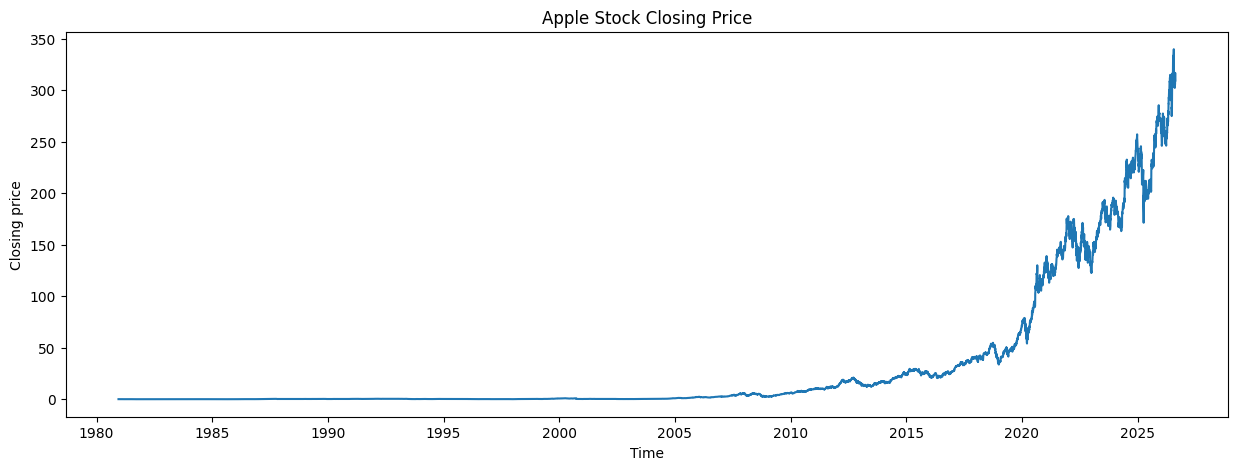

In [ ]:
plt.figure(figsize=(15,5))
plt.plot(df['Close'])
plt.title("Apple Stock Closing Price")
plt.xlabel("Time")
plt.ylabel("Closing price")
plt.show()

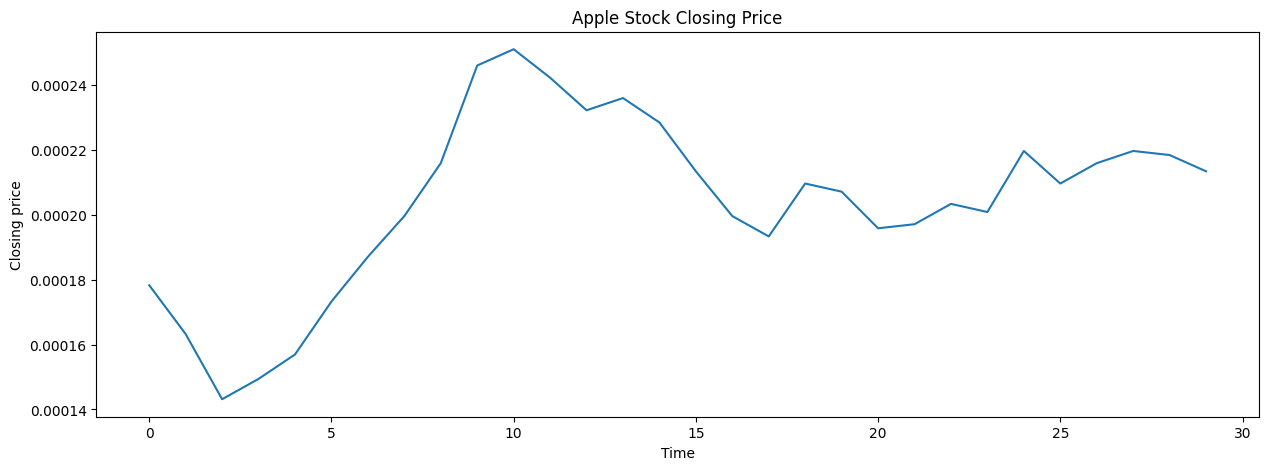

In [ ]:
plt.figure(figsize=(15,5))
plt.plot(x[0])
plt.title("Apple Stock Closing Price")
plt.xlabel("Time")
plt.ylabel("Closing price")
plt.show()

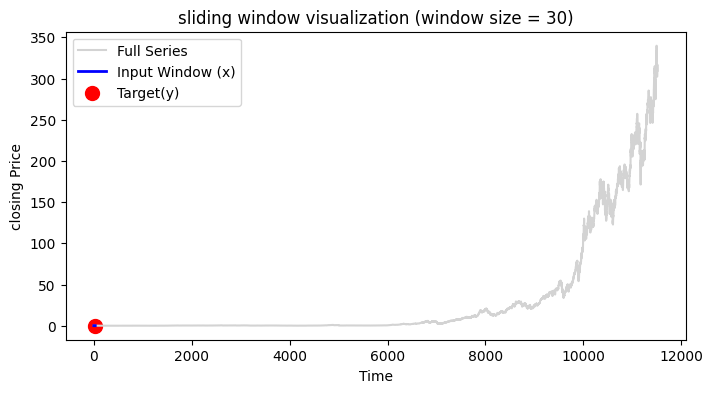

In [ ]:
# choose a sample index
i = 30

window_size = 30
plt.figure(figsize=(8,4))

# full series
plt.plot(df['Close'].values, color = 'lightgray',label = 'Full Series')

# sliding window(x)
plt.plot(range(i-window_size,i),df['Close'].values[i-window_size:i],color='blue',linewidth=2,label='Input Window (x)')

# Target value (y)
plt.scatter(i,df['Close'].values[i],color='red',s=100,label='Target(y)')
plt.title("sliding window visualization (window size = 30)")
plt.xlabel('Time')
plt.ylabel('closing Price')
plt.legend()
plt.show()

In [ ]:
model_Stacked_lstm = Sequential([Input(shape=(window_size,1)),LSTM(50,return_sequences=True), LSTM(50),Dense(1)])
model_Stacked_lstm.compile(optimizer='Adam',loss='mse')
model_Stacked_lstm.summary()
history_Stacked_lstm = model_Stacked_lstm.fit(x_train,y_train,batch_size=32,epochs=10,validation_data=(x_test,y_test))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 1.3101e-05 - val_loss: 5.8175e-04
Epoch 2/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 1.3053e-06 - val_loss: 8.2536e-04
Epoch 3/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.2426e-06 - val_loss: 5.5419e-04
Epoch 4/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 1.1406e-06 - val_loss: 6.2202e-04
Epoch 5/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 9.7042e-07 - val_loss: 3.3788e-04
Epoch 6/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.0910e-06 - val_loss: 6.5661e-04
Epoch 7/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 1.0871e-06 - val_loss: 3.2920e-04
Epoch 8/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 8.5794e-07 - val_loss: 5.4859e-04
Epoch 9/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.1546e-06 - val_loss: 4.0861e-04
Epoch 10/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 8.1702e-07 - val_loss: 7.7585e-04


calculation = (input feature * hidden unit) + (hidden unit * hidden unit) + hidden unit

parameter = calculation * 4

In [ ]:
# model prediction
prediction = model_Stacked_lstm.predict(x_test)
prediction = scaler.inverse_transform(prediction)


72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


In [ ]:
actual = scaler.inverse_transform(y_test)
for i in range(len(prediction)):
  print(f"predicted:{prediction[i][0]:.2f},Actual:{actual[i][0]:.2f}")


predicted:32.46,Actual:33.26
predicted:32.40,Actual:33.40
predicted:32.36,Actual:33.09
predicted:32.29,Actual:33.42
predicted:32.26,Actual:33.63
predicted:32.28,Actual:33.74
predicted:32.33,Actual:33.78
predicted:32.41,Actual:34.25
predicted:32.55,Actual:34.55
predicted:32.74,Actual:34.67
predicted:32.95,Actual:34.79
predicted:33.15,Actual:35.01
predicted:33.36,Actual:34.85
predicted:33.52,Actual:34.83
predicted:33.63,Actual:35.26
predicted:33.75,Actual:35.41
predicted:33.89,Actual:35.57
predicted:34.04,Actual:34.90
predicted:34.08,Actual:34.66
predicted:34.03,Actual:34.48
predicted:33.92,Actual:34.78
predicted:33.83,Actual:36.43
predicted:33.97,Actual:36.06
predicted:34.17,Actual:36.25
predicted:34.40,Actual:36.81
predicted:34.68,Actual:37.11
predicted:34.99,Actual:37.34
predicted:35.31,Actual:36.15
predicted:35.44,Actual:36.65
predicted:35.51,Actual:37.20
predicted:35.62,Actual:37.61
predicted:35.79,Actual:37.46
predicted:35.94,Actual:36.74
predicted:35.97,Actual:36.65
predicted:35.9

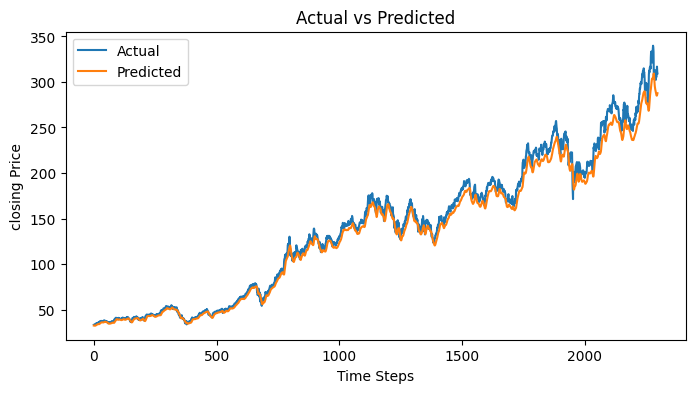

In [ ]:
# Plotting (Actual vs Predicted values)
plt.figure(figsize=(8,4))
plt.plot(actual,label='Actual')
plt.plot(prediction,label='Predicted')
plt.title('Actual vs Predicted')
plt.xlabel('Time Steps')
plt.ylabel('closing Price')
plt.legend()
plt.show()

In [ ]:
model_bidlstm = Sequential([Bidirectional(LSTM(50), input_shape = (window_size,1)),Dense(1)])
model_bidlstm.compile(optimizer='Adam',loss='mse')
model_bidlstm.summary()

history_bi = model_bidlstm.fit(x_train,y_train,batch_size=32,epochs=10,validation_data=(x_test,y_test))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 100)            │        20,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,901 (81.64 KB)

 Trainable params: 20,901 (81.64 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 1.7984e-05 - val_loss: 0.0011
Epoch 2/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 2.2720e-06 - val_loss: 6.7306e-04
Epoch 3/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 2.0272e-06 - val_loss: 5.0878e-04
Epoch 4/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.3759e-06 - val_loss: 3.3002e-04
Epoch 5/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.2133e-06 - val_loss: 3.3563e-04
Epoch 6/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 1.0732e-06 - val_loss: 2.6868e-04
Epoch 7/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 1.0071e-06 - val_loss: 2.1865e-04
Epoch 8/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 9.4679e-07 - val_loss: 2.1005e-04
Epoch 9/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 9.3566e-07 - val_loss: 2.0315e-04
Epoch 10/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 6.9803e-07 - val_loss: 1.9356e-04


Bidirectional LSTM :
calculation1 =
 (input featue * hidden unit) + (hidden unit * hidden unit) + hidden unit

 calculation2 = calculation1 * 4 (gate)

 parameter = calculation2 * 2(b/c bidirectional)

 4th gate is Candidate ceil

Multilayer Lstm : LSTM with decreases units

In [ ]:
batch = 32
model_Multilayer_lstm = Sequential([Input(batch_shape = (batch,window_size,1)),LSTM(100,return_sequences=True),LSTM(50,return_sequences = True),LSTM(25),Dense(1)])
model_Multilayer_lstm.compile(optimizer='Adam',loss='mse')
model_Multilayer_lstm.summary()
history_Multilayer_lstm = model_Multilayer_lstm.fit(x_train,y_train,batch_size=32,epochs=10,validation_data=(x_test,y_test))

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (32, 30, 100)          │        40,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (32, 30, 50)           │        30,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (32, 25)               │         7,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (32, 1)                │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,626 (307.13 KB)

 Trainable params: 78,626 (307.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 1.6205e-05 - val_loss: 0.0076
Epoch 2/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 2.3948e-06 - val_loss: 0.0064
Epoch 3/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 2.2347e-06 - val_loss: 0.0045
Epoch 4/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 2.7309e-06 - val_loss: 0.0036
Epoch 5/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 1.5610e-06 - val_loss: 0.0023
Epoch 6/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 1.3956e-06 - val_loss: 0.0023
Epoch 7/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 1.8092e-06 - val_loss: 0.0035
Epoch 8/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 1.4695e-06 - val_loss: 0.0052
Epoch 9/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 1.3250e-06 - val_loss: 0.0030
Epoch 10/10
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 1.2506e-06 - val_loss: 0.0033


in case of normal lstm we reset the hidden state automatically.

in case of stateful lstm we manually reset the hidden state

normal lstm : 1 sequence length = 30 samples batch size equal to 32 , batch size > sequence length

stateful lstm : seq > Bitch size

In [ ]:
batch = 32
model_stateful_LSTM = Sequential([Input(batch_shape = (batch,window_size,1)),LSTM(50,stateful=True),Dense(1)])
model_stateful_LSTM.compile(optimizer='Adam',loss='mse')
model_stateful_LSTM.summary()

# Truncate x_train and y_train to be a multiple of batch_size
train_samples = (x_train.shape[0] // batch) * batch
x_train_truncated = x_train[:train_samples]
y_train_truncated = y_train[:train_samples]

# Truncate x_test and y_test to be a multiple of batch_size
test_samples = (x_test.shape[0] // batch) * batch
x_test_truncated = x_test[:test_samples]
y_test_truncated = y_test[:test_samples]

history_Stateful_lstm = model_stateful_LSTM.fit(x_train_truncated, y_train_truncated, batch_size=batch, epochs=10, validation_data=(x_test_truncated, y_test_truncated), shuffle=False)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (32, 50)               │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (32, 1)                │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 1.4602e-05 - val_loss: 0.0877
Epoch 2/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1.3697e-04 - val_loss: 0.0788
Epoch 3/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 9.9947e-05 - val_loss: 0.0741
Epoch 4/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 6.9054e-05 - val_loss: 0.0591
Epoch 5/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 7.0745e-05 - val_loss: 0.0592
Epoch 6/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 6.2637e-05 - val_loss: 0.0504
Epoch 7/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 5.2438e-05 - val_loss: 0.0415
Epoch 8/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 4.7824e-05 - val_loss: 0.0354
Epoch 9/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 4.0310e-05 - val_loss: 0.0266
Epoch 10/10
287/287 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 3.3439e-05 - val_loss: 0.0184


Residual LSTM

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# Input
inputs = layers.Input(shape=(10, 64))  # (seq_len, features)

# Layer 1
x1 = layers.LSTM(64, return_sequences=True)(inputs)
res1 = layers.Add()([x1, inputs])   # residual

# Layer 2
x2 = layers.LSTM(64, return_sequences=True)(res1)
res2 = layers.Add()([x2, res1])     # residual

# Final layer
x3 = layers.LSTM(64)(res2)
outputs = layers.Dense(1)(x3)

model = Model(inputs, outputs)

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 10, 64)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_7 (LSTM)       │ (None, 10, 64)    │     33,024 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 10, 64)    │          0 │ lstm_7[0][0],     │
│                     │                   │            │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_8 (LSTM)       │ (None, 10, 64)    │     33,024 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 10, 64)    │          0 │ lstm_8[0][0],     │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_9 (LSTM)       │ (None, 64)        │     33,024 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1)         │         65 │ lstm_9[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 99,137 (387.25 KB)

 Trainable params: 99,137 (387.25 KB)

 Non-trainable params: 0 (0.00 B)

Residual LSTM adds skip connections to standard LSTM so the model learns residuals instead of full mappings, improving gradient flow and performance.

Why Use Residual LSTM?

Helps vanishing gradient problem

Enables deeper LSTM stacks

Improves training stability

Often faster convergence

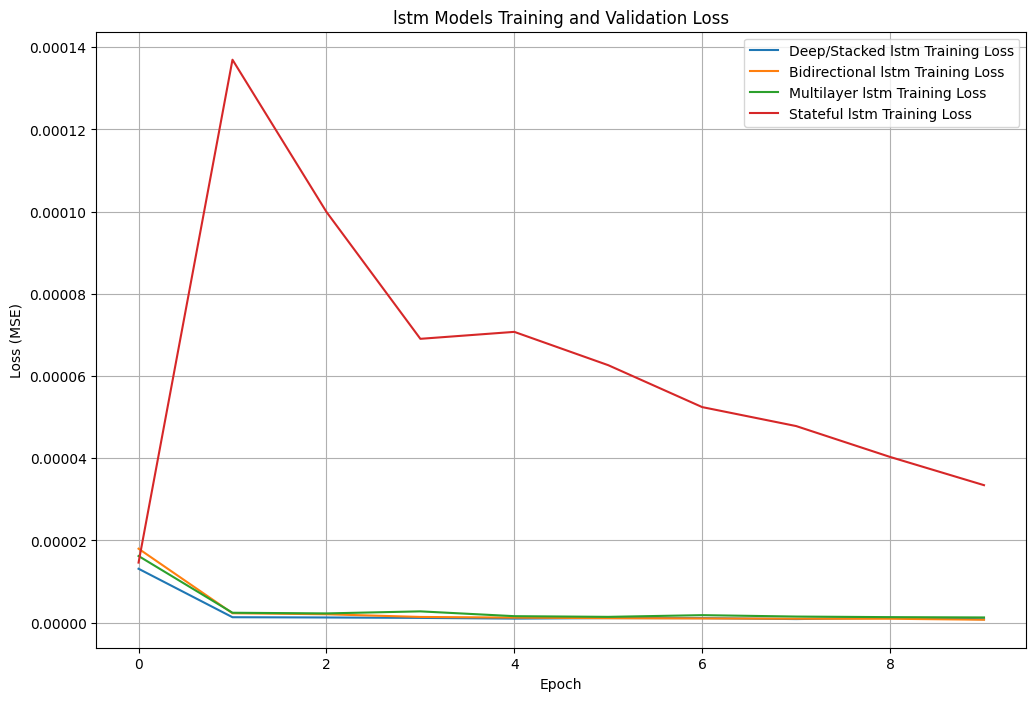

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))


# Plotting Deep/Stacked lstm history
plt.plot(history_Stacked_lstm.history['loss'], label='Deep/Stacked lstm Training Loss')

# Plotting Bidirectional lstm history
plt.plot(history_bi.history['loss'], label='Bidirectional lstm Training Loss')

# Plotting Multilayer lstm history
plt.plot(history_Multilayer_lstm.history['loss'], label='Multilayer lstm Training Loss')

# Plotting Stateful lstm history
plt.plot(history_Stateful_lstm.history['loss'], label='Stateful lstm Training Loss')



plt.title('lstm Models Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)
plt.show()

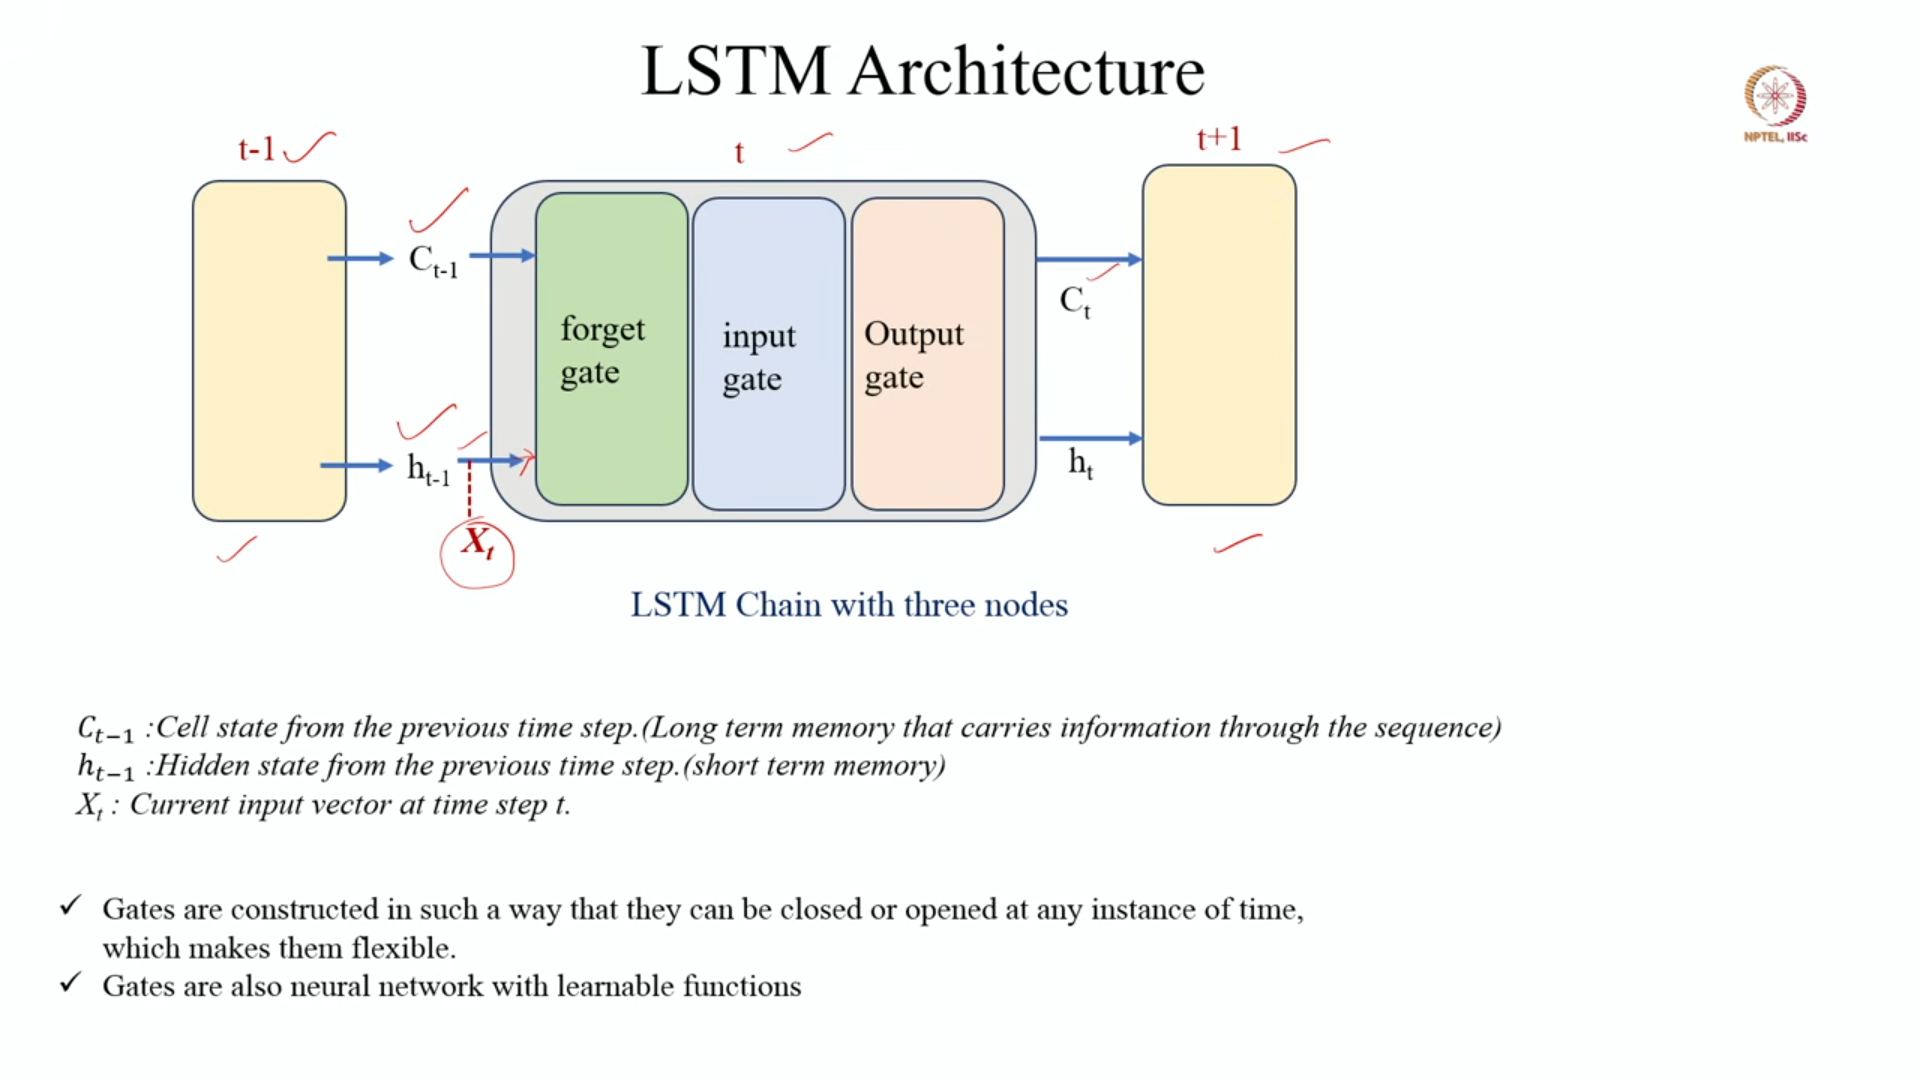

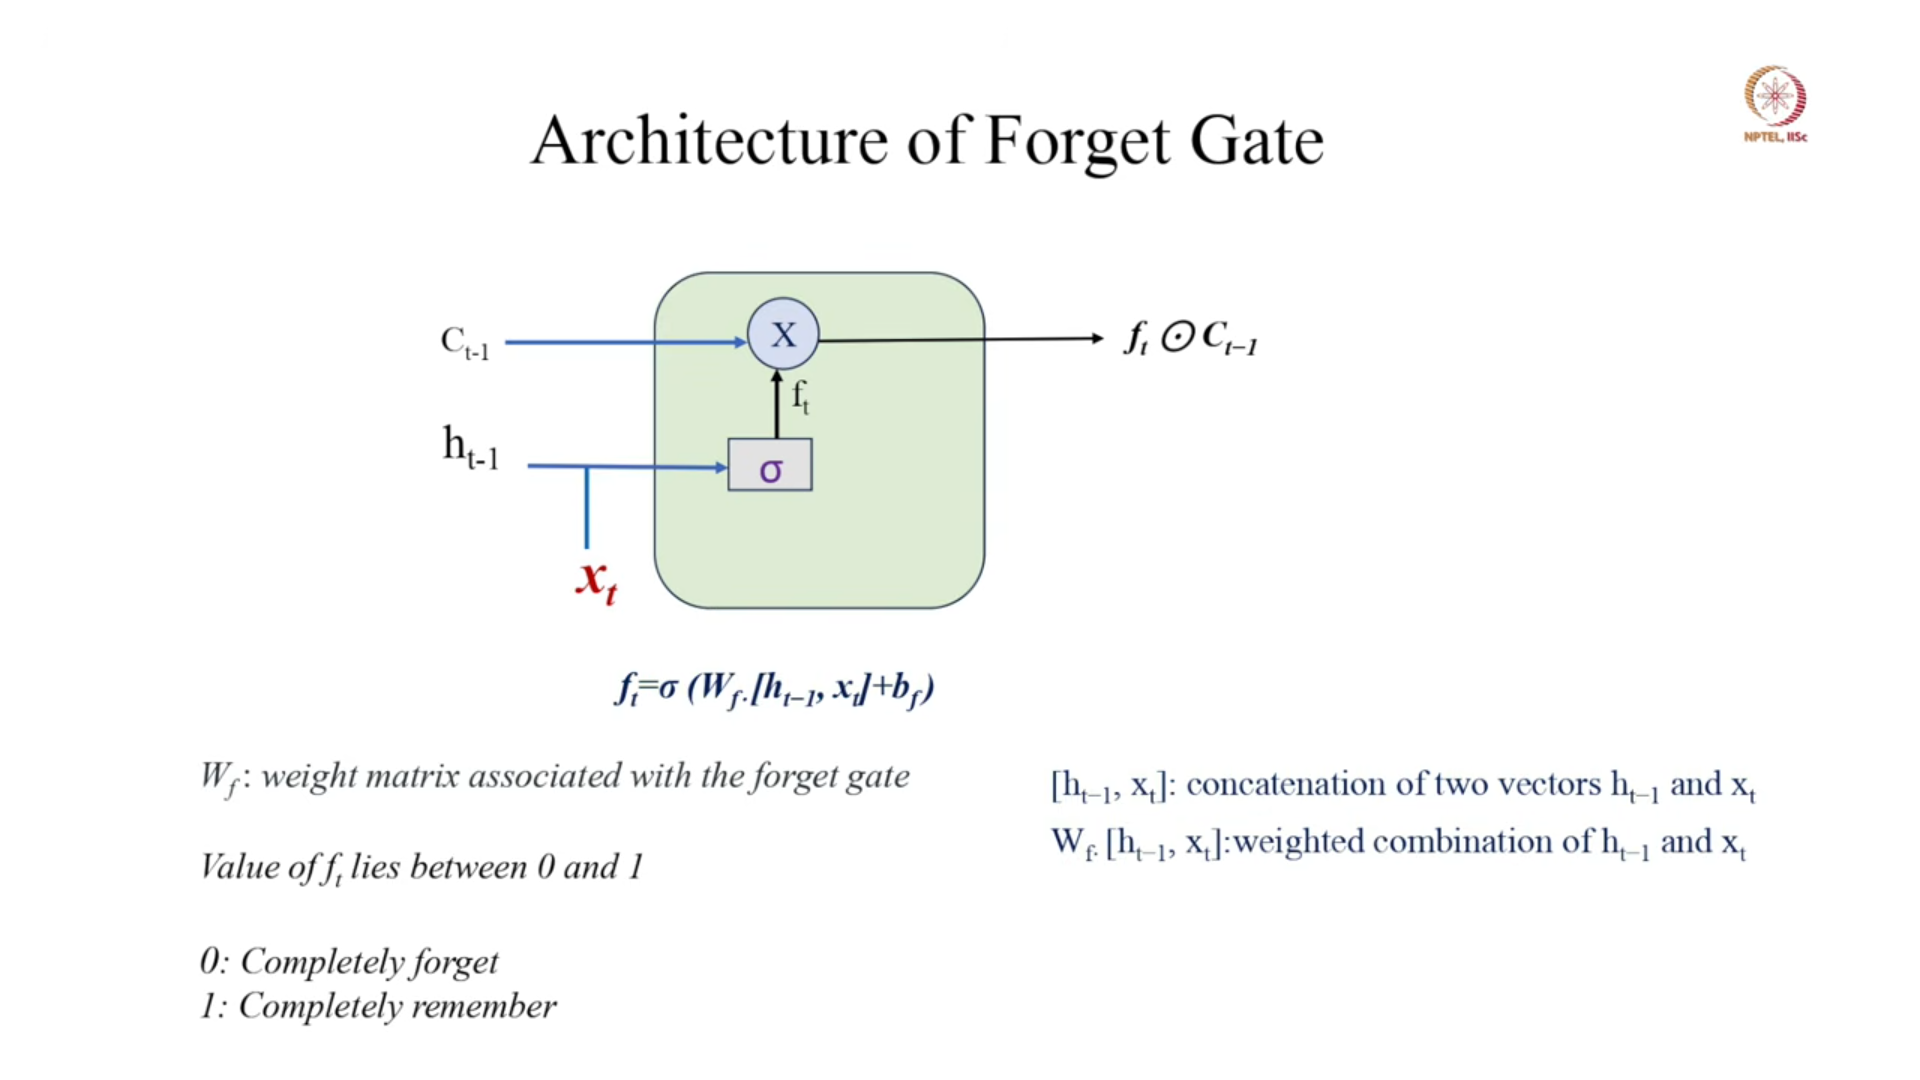

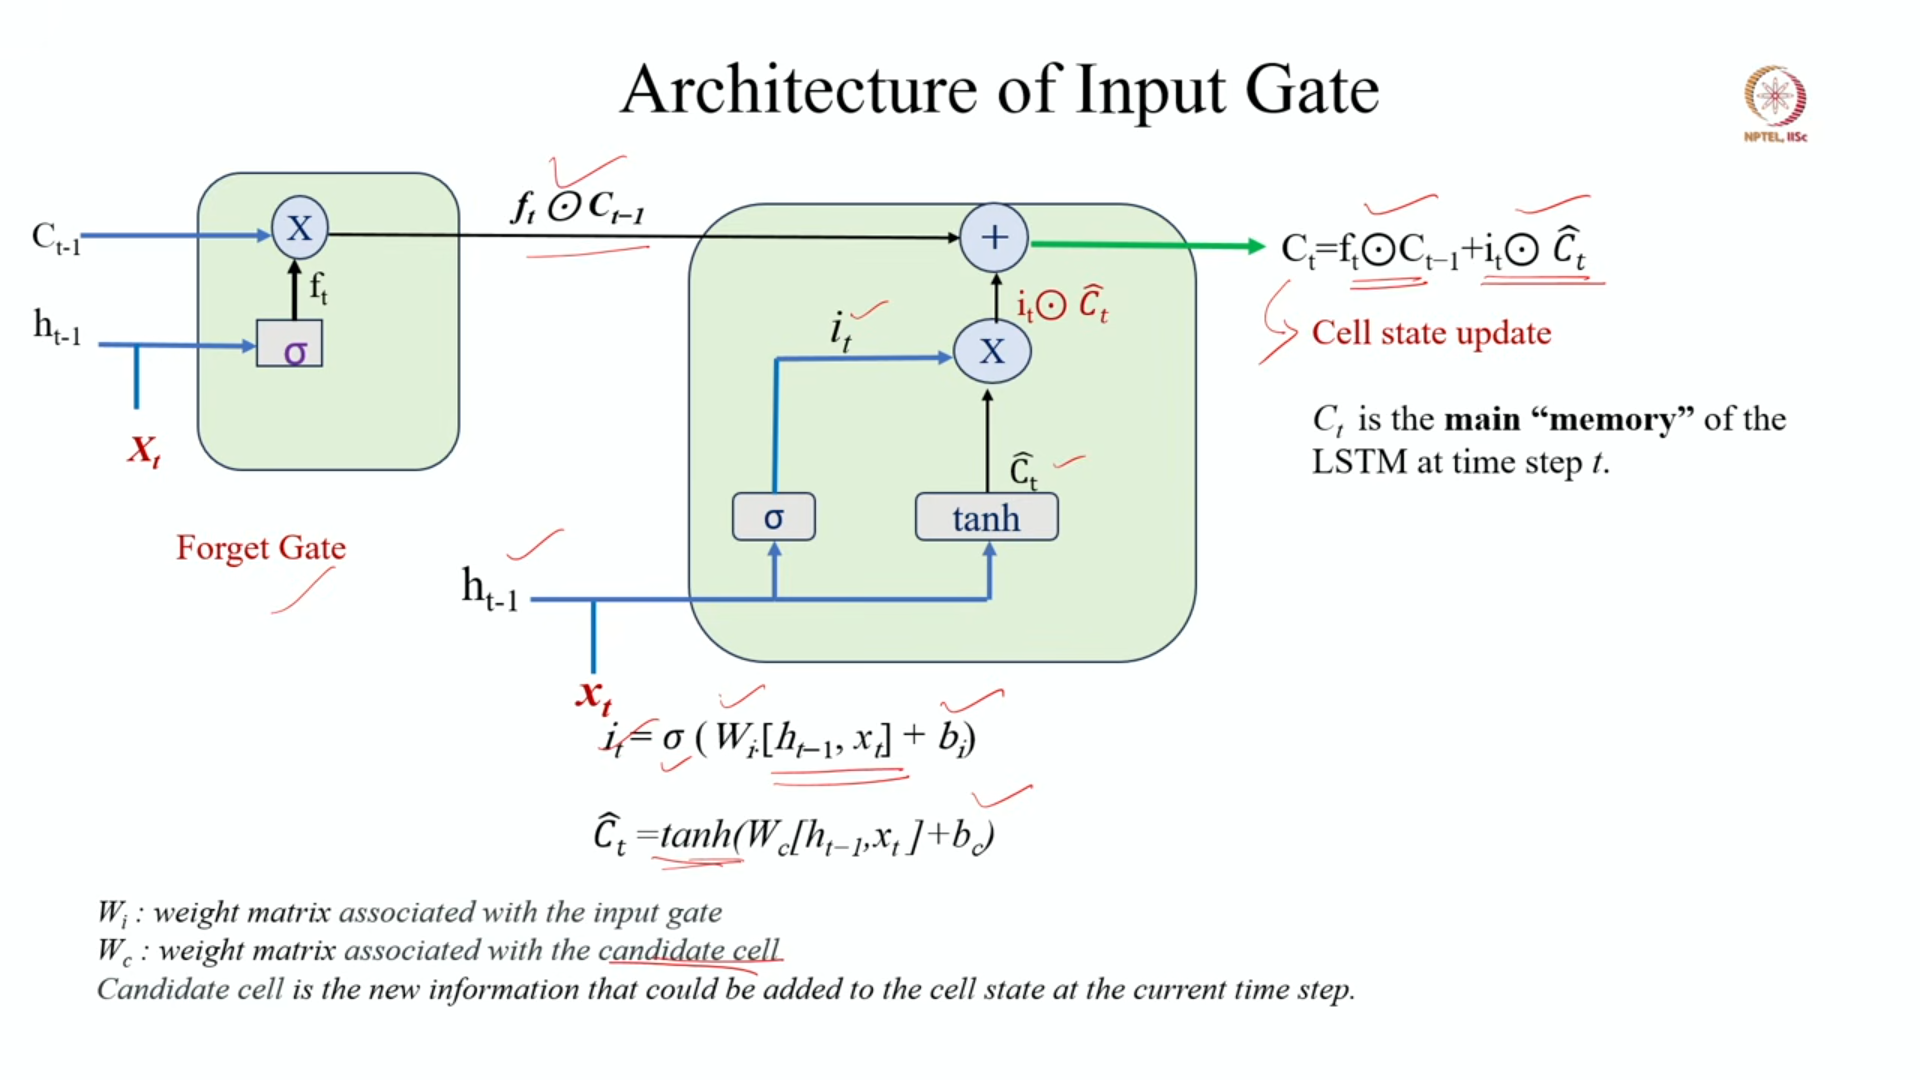

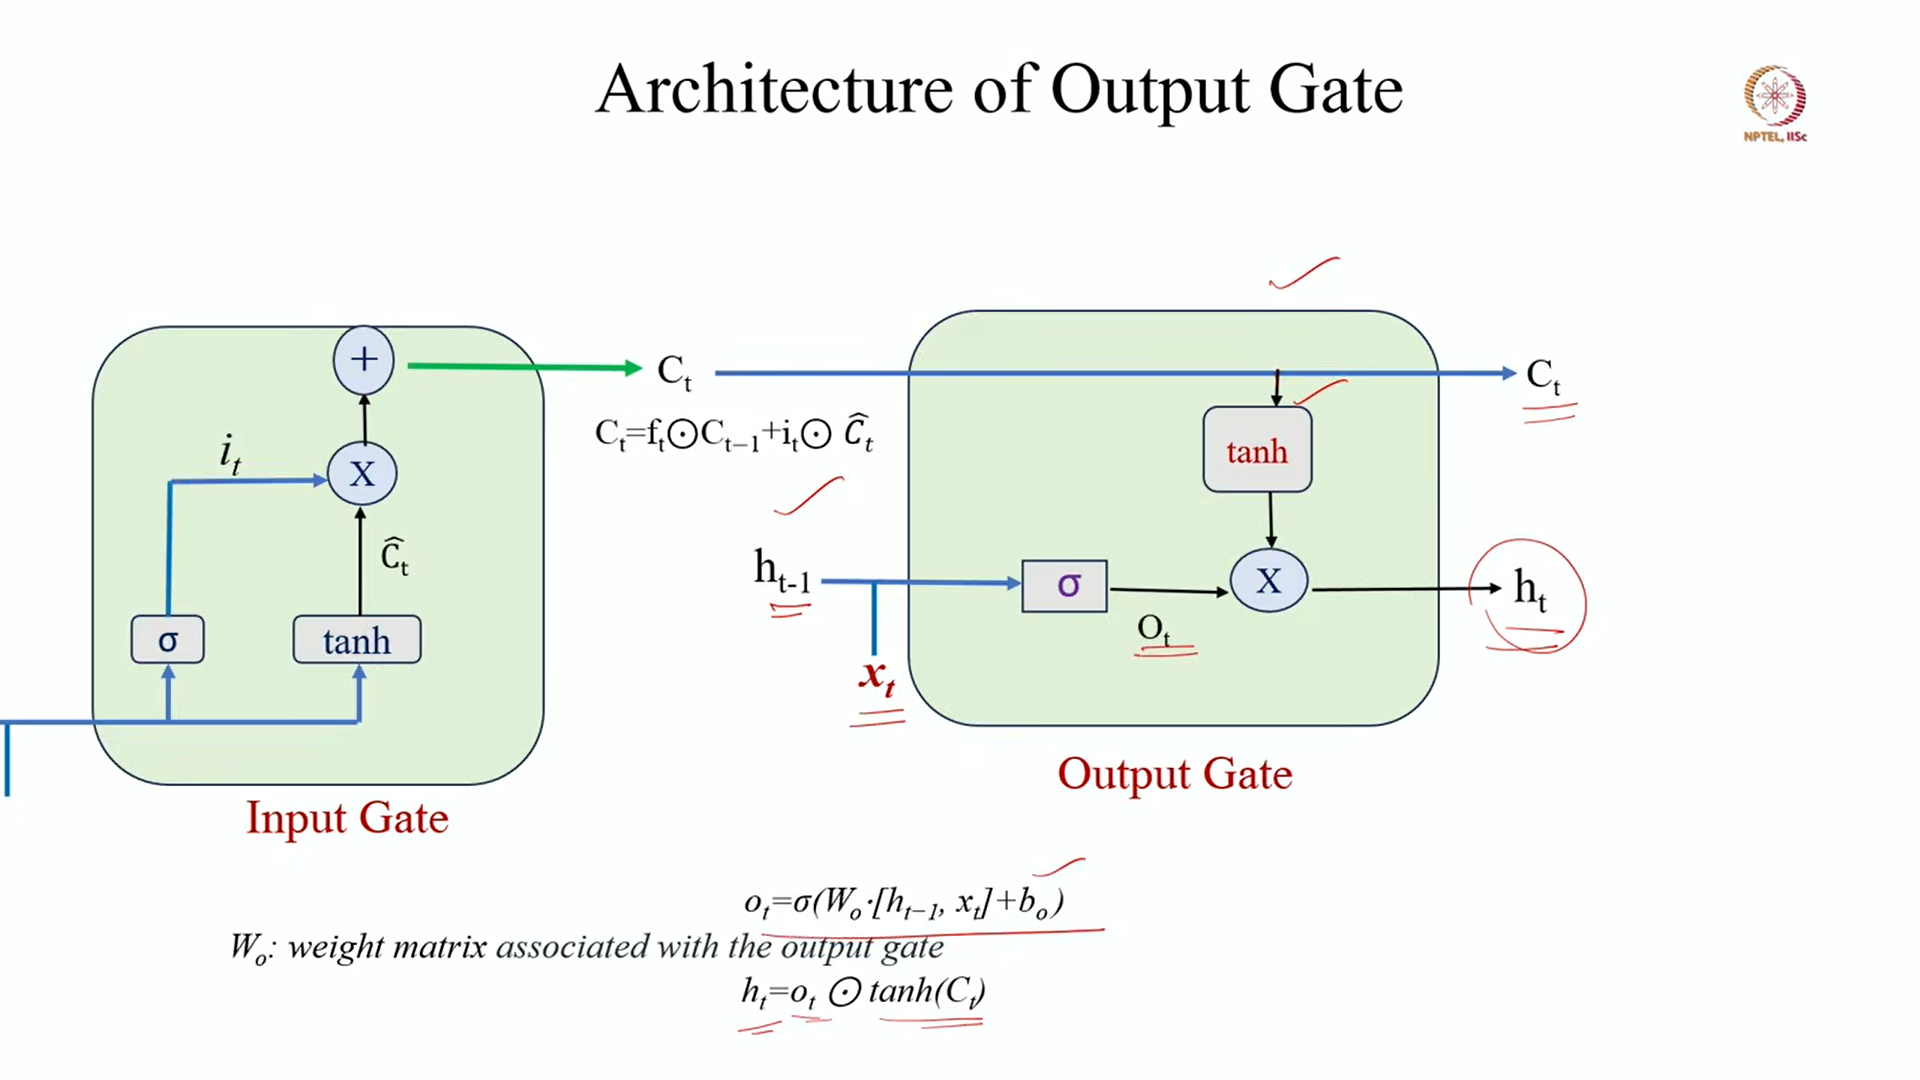

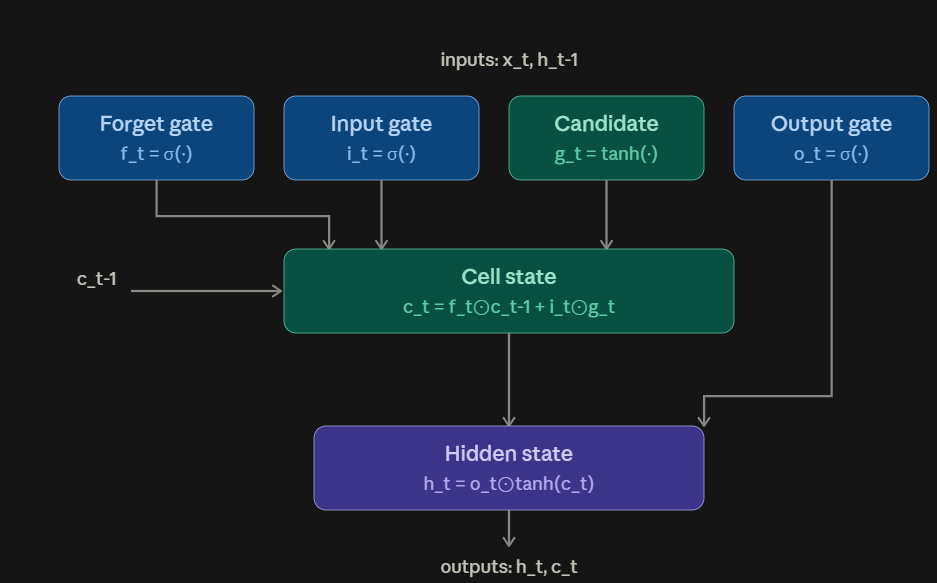

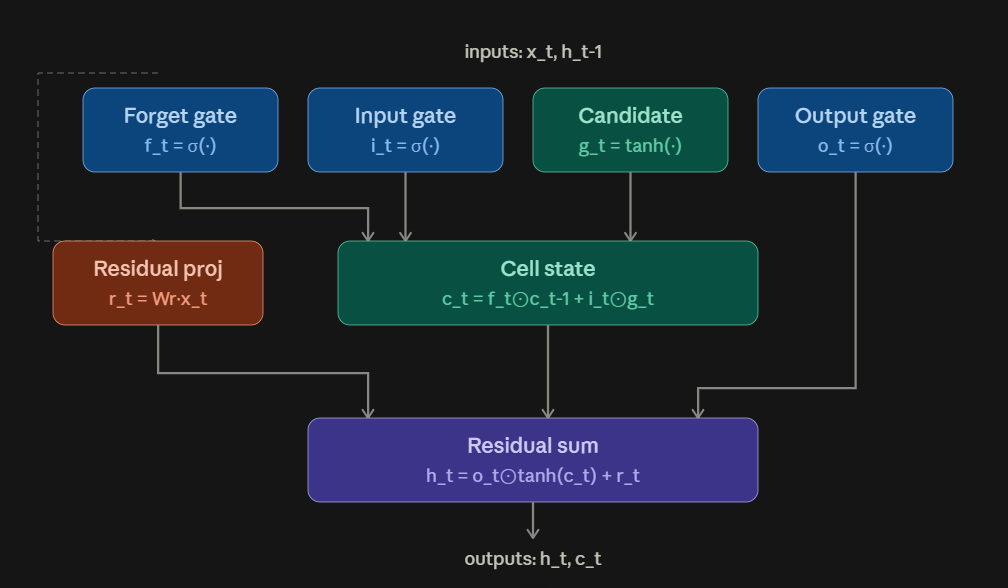

LSTM Implement from Scratch

In [ ]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

class LSTMCell:
    def __init__(self, input_dim, hidden_dim):
        concat_dim = hidden_dim + input_dim

        # Initialize gate weight matrices
        self.W_f = np.random.randn(hidden_dim, concat_dim)
        self.W_i = np.random.randn(hidden_dim, concat_dim)
        self.W_c = np.random.randn(hidden_dim, concat_dim)
        self.W_o = np.random.randn(hidden_dim, concat_dim)

        # Initialize gate bias vectors
        self.b_f = np.zeros((hidden_dim, 1))
        self.b_i = np.zeros((hidden_dim, 1))
        self.b_c = np.zeros((hidden_dim, 1))
        self.b_o = np.zeros((hidden_dim, 1))

    def forward(self, x_t, h_prev, c_prev):

        concat = np.vstack((h_prev, x_t))


        f_t = sigmoid(np.dot(self.W_f, concat) + self.b_f)


        i_t = sigmoid(np.dot(self.W_i, concat) + self.b_i)


        c_tilde_t = np.tanh(np.dot(self.W_c, concat) + self.b_c)


        o_t = sigmoid(np.dot(self.W_o, concat) + self.b_o)


        c_t = f_t * c_prev + i_t * c_tilde_t


        h_t = o_t * np.tanh(c_t)

        return h_t, c_t

In [ ]:
import numpy as np

# -----------------------------
# Step 1: Sigmoid function
# -----------------------------
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


# -----------------------------
# Step 2: LSTM Cell
# -----------------------------
class LSTMCell:

    def __init__(self, input_dim, hidden_dim):

        self.input_dim = input_dim
        self.hidden_dim = hidden_dim

        concat_dim = hidden_dim + input_dim

        # Weight matrices
        self.W_f = np.random.randn(hidden_dim, concat_dim) * 0.1
        self.W_i = np.random.randn(hidden_dim, concat_dim) * 0.1
        self.W_c = np.random.randn(hidden_dim, concat_dim) * 0.1
        self.W_o = np.random.randn(hidden_dim, concat_dim) * 0.1

        # Bias
        self.b_f = np.zeros((hidden_dim, 1))
        self.b_i = np.zeros((hidden_dim, 1))
        self.b_c = np.zeros((hidden_dim, 1))
        self.b_o = np.zeros((hidden_dim, 1))


    # -----------------------------
    # Step 3: Forward pass
    # -----------------------------
    def forward(self, x_t, h_prev, c_prev):

        # Combine hidden state and input
        concat = np.vstack((h_prev, x_t))

        print("\nconcat:")
        print(concat)
        print("concat shape:", concat.shape)

        # Forget gate
        f_t = sigmoid(
            np.dot(self.W_f, concat) + self.b_f
        )

        # Input gate
        i_t = sigmoid(
            np.dot(self.W_i, concat) + self.b_i
        )

        # Candidate cell state
        c_tilde_t = np.tanh(
            np.dot(self.W_c, concat) + self.b_c
        )

        # Output gate
        o_t = sigmoid(
            np.dot(self.W_o, concat) + self.b_o
        )

        # New cell state
        c_t = f_t * c_prev + i_t * c_tilde_t

        # New hidden state
        h_t = o_t * np.tanh(c_t)

        return h_t, c_t


# =====================================================
# Step 4: Give input dimensions
# =====================================================

input_dim = 3
hidden_dim = 4


# Create LSTM
lstm = LSTMCell(input_dim, hidden_dim)


# =====================================================
# Step 5: Give actual input
# =====================================================

x_t = np.array([
    [1],
    [2],
    [3]
])

h_prev = np.zeros((hidden_dim, 1))

c_prev = np.zeros((hidden_dim, 1))


# =====================================================
# Step 6: Run LSTM
# =====================================================

h_t, c_t = lstm.forward(
    x_t,
    h_prev,
    c_prev
)


# =====================================================
# Step 7: Print output
# =====================================================

print("\nInput x_t:")
print(x_t)

print("\nPrevious hidden state h_prev:")
print(h_prev)

print("\nPrevious cell state c_prev:")
print(c_prev)

print("\nNew hidden state h_t:")
print(h_t)

print("\nNew cell state c_t:")
print(c_t)

print("\nh_t shape:", h_t.shape)
print("c_t shape:", c_t.shape)


concat:
[[0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [2.]
 [3.]]
concat shape: (7, 1)

Input x_t:
[[1]
 [2]
 [3]]

Previous hidden state h_prev:
[[0.]
 [0.]
 [0.]
 [0.]]

Previous cell state c_prev:
[[0.]
 [0.]
 [0.]
 [0.]]

New hidden state h_t:
[[0.00674777]
 [0.10345755]
 [0.12256538]
 [0.0235603 ]]

New cell state c_t:
[[0.01880157]
 [0.24462346]
 [0.28078826]
 [0.05370707]]

h_t shape: (4, 1)
c_t shape: (4, 1)


Residual–LSTM architecture

### **LSTM With Projection**
Bade hidden state se accuracy achhi milti hai, par recurrent matrix bhi bada ho jaata hai — projection use karke usse chhota kar dete hain, speed aur memory bachane ke liye.

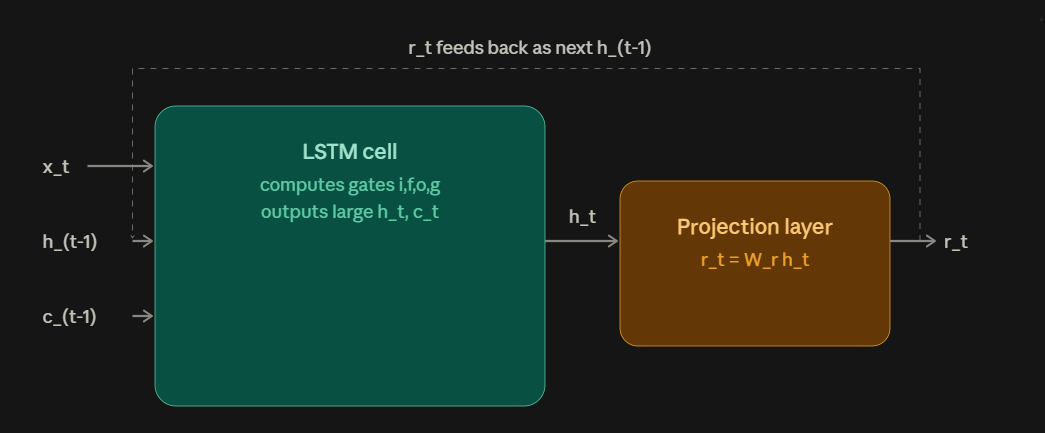

### BILSTM

Generally in normal LSTM network we take output directly as shown in first figure but in bidirectional LSTM network output of forward and backward layer at each stage is given to activation layer which is a neural network and output of this activation layer is considered. This output contains the information or relation of past and future word also.

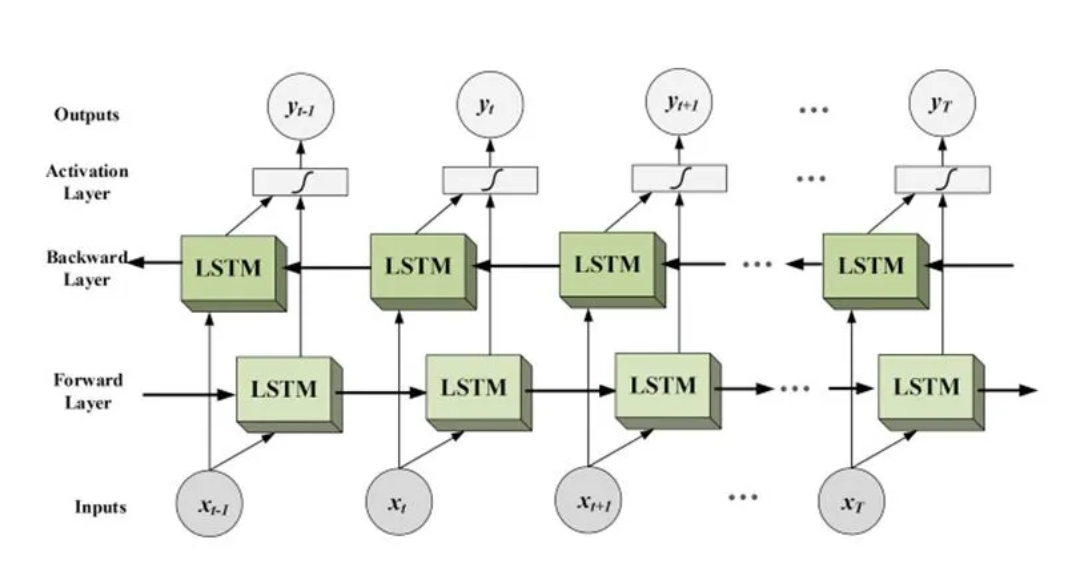

### DEEP / Stacked LSTM
A stacked LSTM contains multiple layers where the output of one feeds into the next. It is used to capture deeply complex, hierarchical features in sequential data, significantly improving overall predictive power and model accuracy.

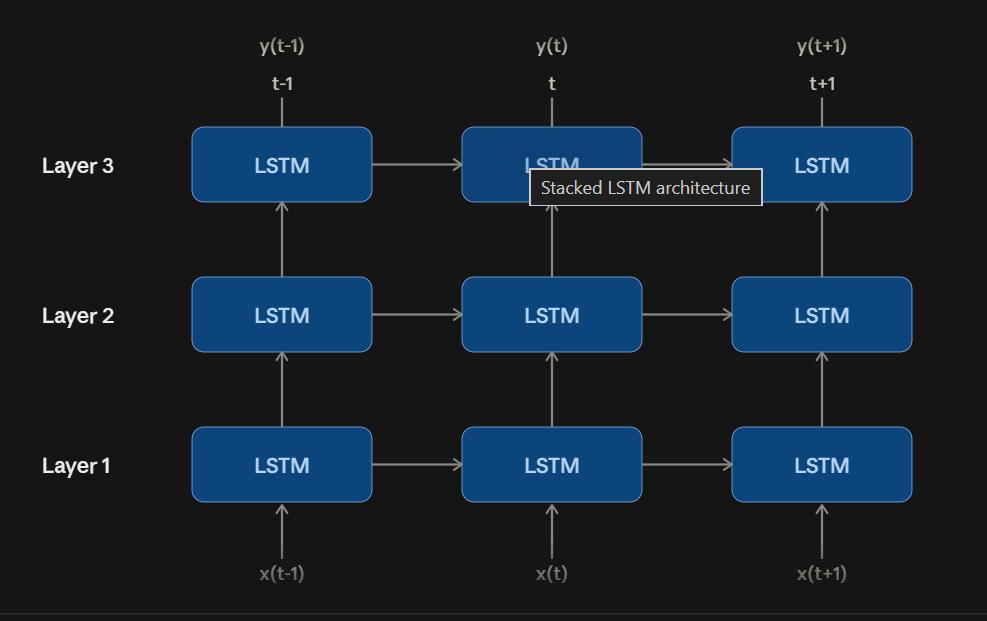

### ConvLSTM
ConvLSTM replaces internal matrix multiplications of a standard LSTM with convolution operations. It is used to process complex spatiotemporal data, like video streams or weather radar, because it simultaneously captures spatial features and temporal dependencies.

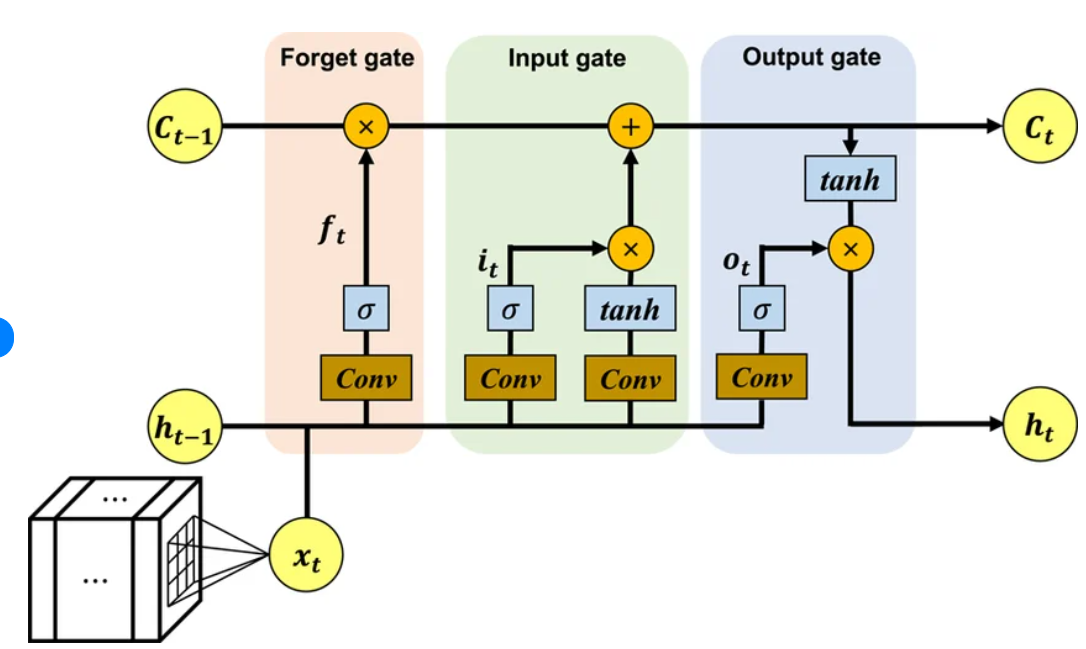

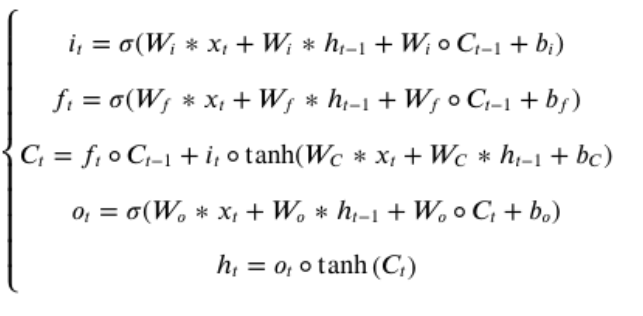

### Attention Based LSTM Architecture

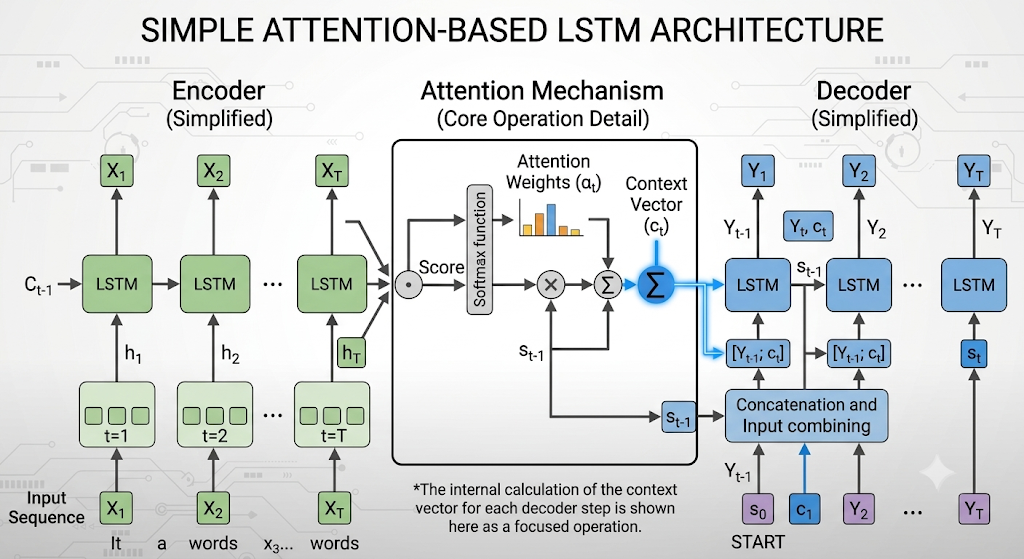

### Layer Normalized LSTM Architecture


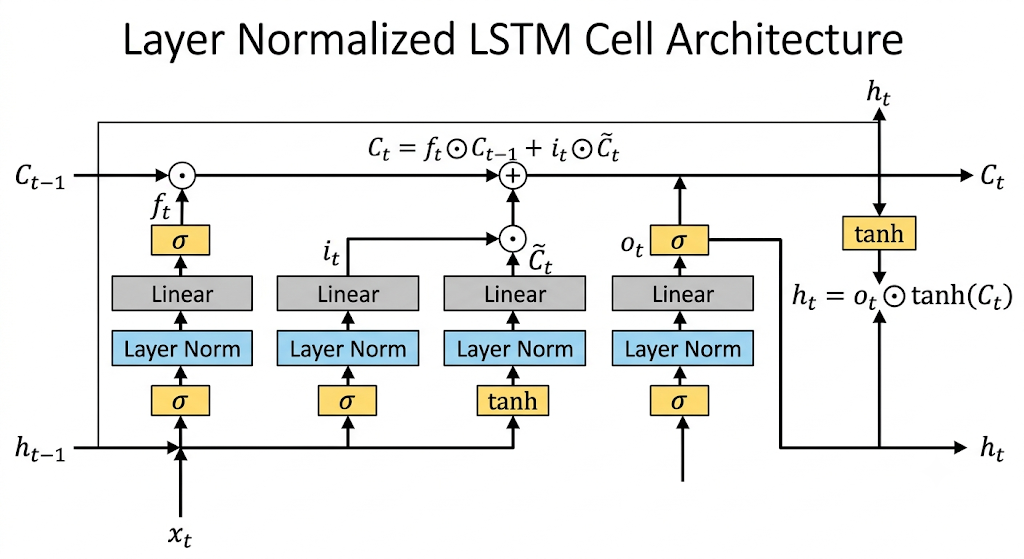

Layer normalization standardizes inputs across features for a single training sample using the following sequence of operations:

1. **Mean calculation ($\mu$):**

$$\mu = \frac{1}{d} \sum_{i=1}^{d} x_i$$


2. **Variance calculation ($\sigma^2$):**

$$\sigma^2 = \frac{1}{d} \sum_{i=1}^{d} (x_i - \mu)^2$$


3. **Normalization ($\hat{x}_i$):**

$$\hat{x}_i = \frac{x_i - \mu}{\sqrt{\sigma^2 + \epsilon}}$$


4. **Scale and Shift ($y_i$):**

$$y_i = \gamma \odot \hat{x}_i + \beta$$



**Single Combined Expression**

$$y = \gamma \odot \left( \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} \right) + \beta$$

**Variable Definitions**

* **$x$**: Input vector across $d$ feature dimensions for a single data point.
* **$\mu$**: Mean calculated across the feature dimension.
* **$\sigma^2$**: Variance calculated across the feature dimension.
* **$\epsilon$**: Small constant (e.g., $10^{-5}$) added for numerical stability to avoid division by zero.
* **$\gamma$, $\beta$**: Learnable scale and shift parameters of dimension $d$.
* **$\odot$**: Element-wise multiplication.
* **$y$**: Normalized and scaled output vector.

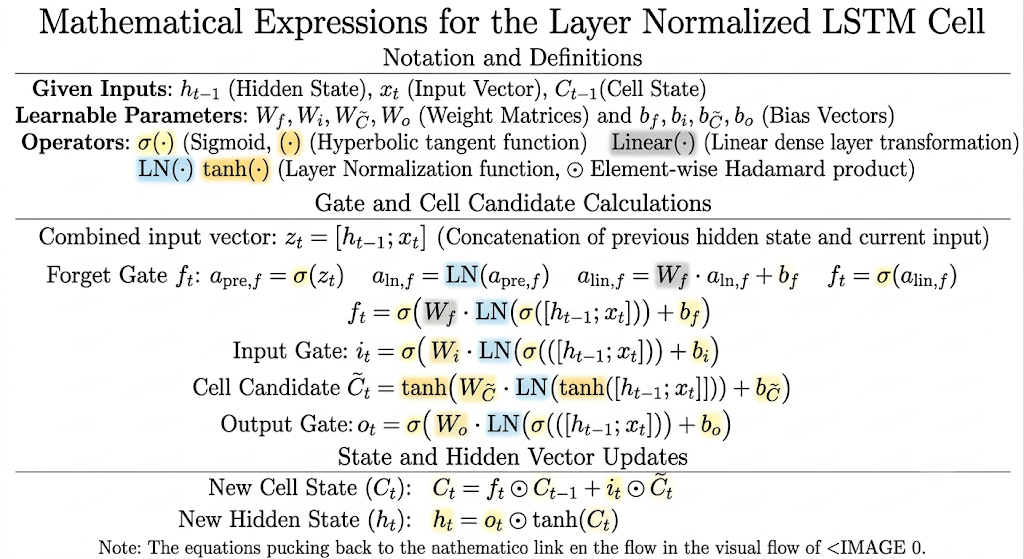

Standard LSTM Implementation

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Load Data
df = pd.read_csv('/content/POWER_Point_Daily_T2M_only.csv')
data = df[['T2M_Temperature_C']].values

# Normalize data to [0, 1] range for stable LSTM convergence
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# 2. Construct Sequence Lookback Windows
def create_sequences(dataset, seq_length=30):
    X, y = [], []
    for i in range(len(dataset) - seq_length):
        X.append(dataset[i:i + seq_length])
        y.append(dataset[i + seq_length])
    return np.array(X), np.array(y)

SEQ_LENGTH = 30
X, y = create_sequences(scaled_data, SEQ_LENGTH)

# Train (70%), Validation (15%), Test (15%) Splits
train_size = int(len(X) * 0.70)
val_size = int(len(X) * 0.15)

X_train, y_train = X[:train_size], y[:train_size]
X_val, y_val = X[train_size:train_size + val_size], y[train_size:train_size + val_size]
X_test, y_test = X[train_size + val_size:], y[train_size + val_size:]

# PyTorch DataLoaders
train_loader = DataLoader(TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32)), batch_size=64, shuffle=False)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32)), batch_size=64, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.float32)), batch_size=64, shuffle=False)

# 3. Standard LSTM Architecture
class StandardLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, output_size=1):
        super(StandardLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])  # Extract prediction from the final time step
        return out

model = StandardLSTM()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 4. Training Loop with Auto-Closed Epochs (Early Stopping)
MAX_EPOCHS = 100
PATIENCE = 10
best_val_loss = float('inf')
patience_counter = 0
best_model_weights = None

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_loss = 0.0
    for bx, by in train_loader:
        optimizer.zero_grad()
        output = model(bx)
        loss = criterion(output, by)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * bx.size(0)
    train_loss /= len(train_loader.dataset)

    # Validation Phase
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for bx, by in val_loader:
            output = model(bx)
            loss = criterion(output, by)
            val_loss += loss.item() * bx.size(0)
    val_loss /= len(val_loader.dataset)

    print(f"Epoch {epoch:03d} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")

    # Auto-Close Trigger based on Minimum Validation Score
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = model.state_dict().copy()
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f"\n[Auto-Closed] Epochs stopped early at Epoch {epoch}.")
        print(f"Minimum Validation Loss Score Achieved: {best_val_loss:.6f}")
        break

# 5. Evaluate Best Model
model.load_state_dict(best_model_weights)
model.eval()

predictions, actuals = [], []
with torch.no_grad():
    for bx, by in test_loader:
        pred = model(bx)
        predictions.append(pred.numpy())
        actuals.append(by.numpy())

predictions = np.vstack(predictions)
actuals = np.vstack(actuals)

# Rescale predictions back to actual temperature (°C)
pred_orig = scaler.inverse_transform(predictions)
actual_orig = scaler.inverse_transform(actuals)

# 6. Accuracy and Error Calculation
mse = mean_squared_error(actual_orig, pred_orig)
rmse = np.sqrt(mse)
mae = mean_absolute_error(actual_orig, pred_orig)
r2 = r2_score(actual_orig, pred_orig)
mape = np.mean(np.abs((actual_orig - pred_orig) / actual_orig)) * 100
accuracy_pct = 100 - mape

print("\n=== Model Evaluation Results ===")
print(f"Mean Absolute Error (MAE): {mae:.4f} °C")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} °C")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R² Score: {r2:.4f}")
print(f"Accuracy Percentage: {accuracy_pct:.2f}%")

Epoch 001 | Train Loss: 0.040543 | Val Loss: 0.004443
Epoch 002 | Train Loss: 0.004451 | Val Loss: 0.003463
Epoch 003 | Train Loss: 0.003756 | Val Loss: 0.002987
Epoch 004 | Train Loss: 0.003763 | Val Loss: 0.002738
Epoch 005 | Train Loss: 0.003119 | Val Loss: 0.002720
Epoch 006 | Train Loss: 0.003209 | Val Loss: 0.002252
Epoch 007 | Train Loss: 0.002548 | Val Loss: 0.002219
Epoch 008 | Train Loss: 0.002599 | Val Loss: 0.001784
Epoch 009 | Train Loss: 0.001992 | Val Loss: 0.001717
Epoch 010 | Train Loss: 0.002045 | Val Loss: 0.001403
Epoch 011 | Train Loss: 0.001570 | Val Loss: 0.001313
Epoch 012 | Train Loss: 0.001500 | Val Loss: 0.001136
Epoch 013 | Train Loss: 0.001386 | Val Loss: 0.001193
Epoch 014 | Train Loss: 0.001403 | Val Loss: 0.001101
Epoch 015 | Train Loss: 0.001336 | Val Loss: 0.001154
Epoch 016 | Train Loss: 0.001338 | Val Loss: 0.001076
Epoch 017 | Train Loss: 0.001234 | Val Loss: 0.001072
Epoch 018 | Train Loss: 0.001778 | Val Loss: 0.001110
Epoch 019 | Train Loss: 0.00

LSTM with Projection Implementation

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# ==========================================
# 1. DATA PREPARATION
# ==========================================
# Load daily temperature dataset
df = pd.read_csv('/content/POWER_Point_Daily_T2M_only.csv')
data = df['T2M_Temperature_C'].values.reshape(-1, 1)

# Standardize feature values
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

# Create sequence windows (e.g., look back 30 days to predict day 31)
def create_sequences(data, seq_len=30):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i:i + seq_len])
        y.append(data[i + seq_len])
    return np.array(X), np.array(y)

SEQ_LEN = 30
X, y = create_sequences(scaled_data, seq_len=SEQ_LEN)

# Split into Train (70%), Validation (15%), Test (15%)
train_size = int(len(X) * 0.70)
val_size = int(len(X) * 0.15)

X_train, y_train = X[:train_size], y[:train_size]
X_val, y_val = X[train_size:train_size + val_size], y[train_size:train_size + val_size]
X_test, y_test = X[train_size + val_size:], y[train_size + val_size:]

# Convert to PyTorch DataLoaders
batch_size = 128
train_loader = DataLoader(
    TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32)),
    batch_size=batch_size, shuffle=True
)
val_loader = DataLoader(
    TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32)),
    batch_size=batch_size, shuffle=False
)
test_loader = DataLoader(
    TensorDataset(torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.float32)),
    batch_size=batch_size, shuffle=False
)

# ==========================================
# 2. LSTM WITH PROJECTION MODEL
# ==========================================
class LSTMWithProjection(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, proj_size=32, output_size=1):
        super(LSTMWithProjection, self).__init__()
        # Native PyTorch LSTM projection layer via proj_size
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            proj_size=proj_size,
            batch_first=True
        )
        self.fc = nn.Linear(proj_size, output_size)

    def forward(self, x):
        # x shape: (batch_size, sequence_length, input_size)
        lstm_out, _ = self.lstm(x)
        # Extract last time step output: (batch_size, proj_size)
        out = self.fc(lstm_out[:, -1, :])
        return out

model = LSTMWithProjection(input_size=1, hidden_size=64, proj_size=32, output_size=1)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ==========================================
# 3. TRAINING WITH AUTO-CLOSED EPOCHS (EARLY STOPPING)
# ==========================================
MAX_EPOCHS = 100
PATIENCE = 7  # Auto-close training if val loss doesn't improve for 7 epochs
best_val_loss = float('inf')
patience_counter = 0
best_model_weights = None

print("Starting training with Early Stopping...")

for epoch in range(MAX_EPOCHS):
    # Training step
    model.train()
    train_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        preds = model(batch_X)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * batch_X.size(0)
    train_loss /= len(train_loader.dataset)

    # Validation step
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            preds = model(batch_X)
            loss = criterion(preds, batch_y)
            val_loss += loss.item() * batch_X.size(0)
    val_loss /= len(val_loader.dataset)

    print(f"Epoch {epoch+1:02d}/{MAX_EPOCHS} | Train Loss: {train_loss:.5f} | Val Loss: {val_loss:.5f}")

    # Check minimum validation score for Early Stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = model.state_dict().copy()
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n[Auto-Closed Epochs] Training stopped early at Epoch {epoch+1}!")
            print(f"Minimum Validation Loss achieved: {best_val_loss:.5f}")
            break

# Load the best performing model state
model.load_state_dict(best_model_weights)

# ==========================================
# 4. EVALUATION: ACCURACY & ERROR METRICS
# ==========================================
model.eval()
y_preds, y_trues = [], []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        preds = model(batch_X)
        y_preds.append(preds.numpy())
        y_trues.append(batch_y.numpy())

# Scale predictions back to real units (°C)
actual_temp = scaler.inverse_transform(np.vstack(y_trues))
predicted_temp = scaler.inverse_transform(np.vstack(y_preds))

# Calculate Error Metrics
mse = mean_squared_error(actual_temp, predicted_temp)
rmse = np.sqrt(mse)
mae = mean_absolute_error(actual_temp, predicted_temp)

# Calculate Accuracy Metrics
r2 = r2_score(actual_temp, predicted_temp)
mape = np.mean(np.abs((actual_temp - predicted_temp) / actual_temp)) * 100
mape_accuracy = 100 - mape
tolerance_acc = np.mean(np.abs(actual_temp - predicted_temp) <= 1.0) * 100

print("\n" + "="*40)
print("       TEST EVALUATION RESULTS       ")
print("="*40)
print(f"Mean Squared Error (MSE)   : {mse:.4f}")
print(f"Root Mean Sq. Error (RMSE) : {rmse:.4f} °C")
print(f"Mean Absolute Error (MAE)  : {mae:.4f} °C")
print("-" * 40)
print(f"R² Score                   : {r2:.4f}")
print(f"MAPE-based Accuracy        : {mape_accuracy:.2f}%")
print(f"Accuracy (within ±1.0°C)   : {tolerance_acc:.2f}%")
print("="*40)

Starting training with Early Stopping...


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/rnn.py:1169: UserWarning: LSTM with projections is not supported with oneDNN. Using default implementation. (Triggered internally at /pytorch/aten/src/ATen/native/RNN.cpp:1489.)
  result = _VF.lstm(


Epoch 01/100 | Train Loss: 0.26498 | Val Loss: 0.04712
Epoch 02/100 | Train Loss: 0.04643 | Val Loss: 0.03873
Epoch 03/100 | Train Loss: 0.03957 | Val Loss: 0.03363
Epoch 04/100 | Train Loss: 0.03430 | Val Loss: 0.02895
Epoch 05/100 | Train Loss: 0.02945 | Val Loss: 0.02506
Epoch 06/100 | Train Loss: 0.02554 | Val Loss: 0.02199
Epoch 07/100 | Train Loss: 0.02385 | Val Loss: 0.02207
Epoch 08/100 | Train Loss: 0.02380 | Val Loss: 0.02143
Epoch 09/100 | Train Loss: 0.02364 | Val Loss: 0.02161
Epoch 10/100 | Train Loss: 0.02367 | Val Loss: 0.02142
Epoch 11/100 | Train Loss: 0.02367 | Val Loss: 0.02156
Epoch 12/100 | Train Loss: 0.02365 | Val Loss: 0.02154
Epoch 13/100 | Train Loss: 0.02389 | Val Loss: 0.02229
Epoch 14/100 | Train Loss: 0.02357 | Val Loss: 0.02127
Epoch 15/100 | Train Loss: 0.02354 | Val Loss: 0.02141
Epoch 16/100 | Train Loss: 0.02363 | Val Loss: 0.02142
Epoch 17/100 | Train Loss: 0.02357 | Val Loss: 0.02138
Epoch 18/100 | Train Loss: 0.02367 | Val Loss: 0.02139
Epoch 19/1

BiLSTM Implementation

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from torch.utils.data import DataLoader, TensorDataset

# 1. Data Loading and Preprocessing
file_name = "/content/POWER_Point_Daily_T2M_only.csv"
df = pd.read_csv(file_name)

# Assuming the target variable is the last column
data = df.iloc[:, -1].values.reshape(-1, 1)

scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# Create sequences
def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length])
        y.append(data[i + seq_length])
    return np.array(X), np.array(y)

seq_length = 30
X, y = create_sequences(scaled_data, seq_length)

# Split into train (70%), val (15%), and test (15%)
train_size = int(len(X) * 0.7)
val_size = int(len(X) * 0.15)

X_train, y_train = torch.FloatTensor(X[:train_size]), torch.FloatTensor(y[:train_size])
X_val, y_val = torch.FloatTensor(X[train_size:train_size+val_size]), torch.FloatTensor(y[train_size:train_size+val_size])
X_test, y_test = torch.FloatTensor(X[train_size+val_size:]), torch.FloatTensor(y[train_size+val_size:])

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=32, shuffle=False)

# 2. Model Definition
class BiLSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2):
        super(BiLSTMModel, self).__init__()
        # Bidirectional set to True
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, bidirectional=True)
        # hidden_size * 2 because it's bidirectional
        self.fc = nn.Linear(hidden_size * 2, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :]) # Take the last time step
        return out

model = BiLSTMModel()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 3. Early Stopping and Training Loop
epochs = 200
patience = 10
best_val_loss = float('inf')
counter = 0

for epoch in range(epochs):
    model.train()
    train_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation step
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            val_loss += loss.item()

    val_loss /= len(val_loader)

    # Early Stopping Logic (Auto-closing epochs on minimum score)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        torch.save(model.state_dict(), 'best_bilstm.pth') # Save best model
    else:
        counter += 1

    print(f'Epoch [{epoch+1}/{epochs}], Val Loss: {val_loss:.6f}')
    if counter >= patience:
        print(f"Early stopping triggered at epoch {epoch+1}. Restoring best weights.")
        model.load_state_dict(torch.load('best_bilstm.pth'))
        break

# 4. Evaluation (Error and Accuracy Metrics)
model.eval()
with torch.no_grad():
    test_preds = model(X_test).numpy()
    actual_y = y_test.numpy()

# Inverse transform to get real values
test_preds_real = scaler.inverse_transform(test_preds)
actual_y_real = scaler.inverse_transform(actual_y)

# Calculate Errors
mse = mean_squared_error(actual_y_real, test_preds_real)
mae = mean_absolute_error(actual_y_real, test_preds_real)
mape = mean_absolute_percentage_error(actual_y_real, test_preds_real)

# Calculate Accuracy (Heuristic: 100% - MAPE)
accuracy = max(0, 100 - (mape * 100))

print("\n--- Final Results ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Prediction Accuracy (100 - MAPE): {accuracy:.2f}%")

Epoch [1/200], Val Loss: 0.001971
Epoch [2/200], Val Loss: 0.001646
Epoch [3/200], Val Loss: 0.001409
Epoch [4/200], Val Loss: 0.001325
Epoch [5/200], Val Loss: 0.001290
Epoch [6/200], Val Loss: 0.001303
Epoch [7/200], Val Loss: 0.001267
Epoch [8/200], Val Loss: 0.001182
Epoch [9/200], Val Loss: 0.001173
Epoch [10/200], Val Loss: 0.001110
Epoch [11/200], Val Loss: 0.001144
Epoch [12/200], Val Loss: 0.001082
Epoch [13/200], Val Loss: 0.001224
Epoch [14/200], Val Loss: 0.001165
Epoch [15/200], Val Loss: 0.001059
Epoch [16/200], Val Loss: 0.001092
Epoch [17/200], Val Loss: 0.001058
Epoch [18/200], Val Loss: 0.001265
Epoch [19/200], Val Loss: 0.001177
Epoch [20/200], Val Loss: 0.001180
Epoch [21/200], Val Loss: 0.001097
Epoch [22/200], Val Loss: 0.001061
Epoch [23/200], Val Loss: 0.001214
Epoch [24/200], Val Loss: 0.001041
Epoch [25/200], Val Loss: 0.001064
Epoch [26/200], Val Loss: 0.001048
Epoch [27/200], Val Loss: 0.001049
Epoch [28/200], Val Loss: 0.001050
Epoch [29/200], Val Loss: 0.0

Stacked LSTM

In [ ]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from torch.utils.data import TensorDataset, DataLoader
import copy

# -----------------------------------
# 1. Data Preparation
# -----------------------------------
# Load the dataset
df = pd.read_csv("POWER_Point_Daily_T2M_only.csv")

# Assume 'T2M' is the column containing the temperature data
# Adjust the column name if it differs in your CSV
data = df['T2M_Temperature_C'].values.reshape(-1, 1)

# Scale the data to (0, 1) for LSTM
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Create sequences
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        xs.append(data[i:(i + seq_length)])
        ys.append(data[i + seq_length])
    return np.array(xs), np.array(ys)

SEQ_LENGTH = 30 # Use 30 days to predict the next day
X, y = create_sequences(scaled_data, SEQ_LENGTH)

# Split into train (80%) and test (20%)
train_size = int(len(X) * 0.8)
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Convert to PyTorch Tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

# Create DataLoaders
batch_size = 64
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size, shuffle=False)

# -----------------------------------
# 2. Model Definition
# -----------------------------------
class StackedLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, output_size=1):
        super(StackedLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        # num_layers > 1 creates a Stacked LSTM
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # Initialize hidden and cell states
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)

        out, _ = self.lstm(x, (h0, c0))
        # Take the output of the last time step
        out = self.fc(out[:, -1, :])
        return out

model = StackedLSTM(input_size=1, hidden_size=64, num_layers=2, output_size=1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# -----------------------------------
# 3. Training with Early Stopping
# -----------------------------------
EPOCHS = 200
patience = 15 # How many epochs to wait after last minimum loss
best_loss = float('inf')
patience_counter = 0
best_model_weights = None

print("Starting Training...")
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        predictions = model(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * batch_X.size(0)
    train_loss /= len(train_loader.dataset)

    # Validation phase
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch_X, batch_y in test_loader:
            predictions = model(batch_X)
            loss = criterion(predictions, batch_y)
            val_loss += loss.item() * batch_X.size(0)
    val_loss /= len(test_loader.dataset)

    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.5f} | Val Loss: {val_loss:.5f}")

    # Early Stopping Logic
    if val_loss < best_loss:
        best_loss = val_loss
        patience_counter = 0
        best_model_weights = copy.deepcopy(model.state_dict())
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print(f"Early stopping triggered at Epoch {epoch+1}. Minimum Val Loss: {best_loss:.5f}")
        break

# Load the best model weights
model.load_state_dict(best_model_weights)

# -----------------------------------
# 4. Evaluation (Accuracy and Error)
# -----------------------------------
model.eval()
with torch.no_grad():
    test_preds = model(X_test).numpy()

# Inverse transform to get actual temperature values
actual_y = scaler.inverse_transform(y_test.numpy())
predicted_y = scaler.inverse_transform(test_preds)

# Calculate Error Metrics
rmse = np.sqrt(mean_squared_error(actual_y, predicted_y))
mae = mean_absolute_error(actual_y, predicted_y)

# Calculate "Accuracy" Metric (R2 Score)
r2 = r2_score(actual_y, predicted_y)

print("\n--- Final Evaluation Metrics ---")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Accuracy (R-Squared Score): {r2:.4f}")

Starting Training...
Epoch 1/200 | Train Loss: 0.02064 | Val Loss: 0.00393
Epoch 2/200 | Train Loss: 0.00386 | Val Loss: 0.00334
Epoch 3/200 | Train Loss: 0.00341 | Val Loss: 0.00317
Epoch 4/200 | Train Loss: 0.00308 | Val Loss: 0.00283
Epoch 5/200 | Train Loss: 0.00281 | Val Loss: 0.00256
Epoch 6/200 | Train Loss: 0.00241 | Val Loss: 0.00192
Epoch 7/200 | Train Loss: 0.00201 | Val Loss: 0.00171
Epoch 8/200 | Train Loss: 0.00174 | Val Loss: 0.00144
Epoch 9/200 | Train Loss: 0.00157 | Val Loss: 0.00133
Epoch 10/200 | Train Loss: 0.00151 | Val Loss: 0.00132
Epoch 11/200 | Train Loss: 0.00145 | Val Loss: 0.00141
Epoch 12/200 | Train Loss: 0.00147 | Val Loss: 0.00119
Epoch 13/200 | Train Loss: 0.00138 | Val Loss: 0.00124
Epoch 14/200 | Train Loss: 0.00140 | Val Loss: 0.00118
Epoch 15/200 | Train Loss: 0.00137 | Val Loss: 0.00147
Epoch 16/200 | Train Loss: 0.00139 | Val Loss: 0.00118
Epoch 17/200 | Train Loss: 0.00137 | Val Loss: 0.00122
Epoch 18/200 | Train Loss: 0.00136 | Val Loss: 0.0012

ConvLSTM Architecture

In [ ]:


import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import copy
import os

# ----------------------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------------------
CSV_PATH        = "/content/POWER_Point_Daily_T2M_only.csv"
TARGET_COL      = "T2M_Temperature_C"

LOOKBACK        = 30          # days of history fed to the model
CHANNELS        = 1           # feature channels per frame
HEIGHT          = 1           # spatial height  (1 = point data, no grid)
WIDTH           = 1           # spatial width   (1 = point data, no grid)

TRAIN_FRAC      = 0.70
VAL_FRAC        = 0.15        # remaining goes to test

BATCH_SIZE      = 64
HIDDEN_DIMS     = [16, 8]     # one entry per ConvLSTM layer
KERNEL_SIZE     = 3
MAX_EPOCHS      = 100
LEARNING_RATE   = 1e-3
EARLY_STOP_PATIENCE = 8       # epochs with no improvement before auto-stop
EARLY_STOP_MIN_DELTA = 1e-5

TOLERANCE_C     = 1.0         # +/- degrees C considered a "correct" prediction

OUT_DIR         = "/mnt/user-data/outputs"
os.makedirs(OUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)


# ----------------------------------------------------------------------------
# 1. DATA LOADING & WINDOWING
# ----------------------------------------------------------------------------
def load_series(csv_path, target_col):
    df = pd.read_csv(csv_path)
    series = df[target_col].astype(float).values.reshape(-1, 1)
    return series


def make_windows(scaled_series, lookback):
    """Turn a 1D scaled series into (X, y) sliding windows.
    X shape -> (N, lookback)   y shape -> (N,)
    """
    X, y = [], []
    for i in range(len(scaled_series) - lookback):
        X.append(scaled_series[i:i + lookback, 0])
        y.append(scaled_series[i + lookback, 0])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


class TemperatureDataset(Dataset):
    """Reshapes each window into ConvLSTM's expected 5D input:
    (seq_len, channels, height, width)."""
    def __init__(self, X, y, channels, height, width):
        self.X = X
        self.y = y
        self.channels, self.height, self.width = channels, height, width

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        seq = self.X[idx]                                   # (lookback,)
        seq = seq.reshape(-1, self.channels, self.height, self.width)
        return torch.from_numpy(seq).float(), torch.tensor(self.y[idx], dtype=torch.float32)


# ----------------------------------------------------------------------------
# 2. CONVLSTM (implemented from scratch — PyTorch has no built-in version)
# ----------------------------------------------------------------------------
class ConvLSTMCell(nn.Module):
    def __init__(self, in_channels, hidden_channels, kernel_size):
        super().__init__()
        padding = kernel_size // 2
        # one conv produces all 4 gates (i, f, o, g) at once
        self.conv = nn.Conv2d(
            in_channels + hidden_channels,
            4 * hidden_channels,
            kernel_size=kernel_size,
            padding=padding,
        )
        self.hidden_channels = hidden_channels

    def forward(self, x, h_prev, c_prev):
        combined = torch.cat([x, h_prev], dim=1)             # (B, C_in+C_hid, H, W)
        gates = self.conv(combined)
        i, f, o, g = torch.split(gates, self.hidden_channels, dim=1)
        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)
        c_next = f * c_prev + i * g
        h_next = o * torch.tanh(c_next)
        return h_next, c_next

    def init_hidden(self, batch_size, height, width, device):
        return (
            torch.zeros(batch_size, self.hidden_channels, height, width, device=device),
            torch.zeros(batch_size, self.hidden_channels, height, width, device=device),
        )


class ConvLSTM(nn.Module):
    """Stack of ConvLSTMCells. Returns the last hidden state of the last layer."""
    def __init__(self, in_channels, hidden_dims, kernel_size):
        super().__init__()
        self.num_layers = len(hidden_dims)
        cells = []
        for layer in range(self.num_layers):
            cur_in = in_channels if layer == 0 else hidden_dims[layer - 1]
            cells.append(ConvLSTMCell(cur_in, hidden_dims[layer], kernel_size))
        self.cells = nn.ModuleList(cells)

    def forward(self, x):
        # x: (B, T, C, H, W)
        B, T, C, H, W = x.shape
        layer_input = x
        last_h = None
        for layer_idx, cell in enumerate(self.cells):
            h, c = cell.init_hidden(B, H, W, x.device)
            outputs = []
            for t in range(T):
                h, c = cell(layer_input[:, t], h, c)
                outputs.append(h)
            layer_input = torch.stack(outputs, dim=1)        # (B, T, hidden, H, W)
            last_h = h
        return last_h                                        # (B, hidden_last, H, W)


class ConvLSTMForecaster(nn.Module):
    def __init__(self, in_channels, hidden_dims, kernel_size, height, width):
        super().__init__()
        self.convlstm = ConvLSTM(in_channels, hidden_dims, kernel_size)
        flat_dim = hidden_dims[-1] * height * width
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        h_last = self.convlstm(x)
        return self.head(h_last).squeeze(-1)


# ----------------------------------------------------------------------------
# 3. EARLY STOPPING  ("auto-close epochs at minimum validation score")
# ----------------------------------------------------------------------------
class EarlyStopping:
    def __init__(self, patience, min_delta):
        self.patience = patience
        self.min_delta = min_delta
        self.best_score = float("inf")
        self.best_epoch = -1
        self.counter = 0
        self.best_state = None
        self.stop = False

    def step(self, val_loss, model, epoch):
        if val_loss < self.best_score - self.min_delta:
            self.best_score = val_loss
            self.best_epoch = epoch
            self.counter = 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True
        return self.stop

    def restore_best(self, model):
        if self.best_state is not None:
            model.load_state_dict(self.best_state)
        return model


# ----------------------------------------------------------------------------
# 4. METRICS
# ----------------------------------------------------------------------------
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-6, None))) * 100
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "MAPE_%": mape, "R2": r2}


def accuracy_metrics(y_true, y_pred, tolerance):
    # 1) Tolerance-based "accuracy": prediction counts as correct if within +/- tolerance
    tol_acc = np.mean(np.abs(y_true - y_pred) <= tolerance) * 100

    # 2) Directional accuracy: did the model get the up/down trend right?
    true_dir = np.sign(np.diff(y_true))
    pred_dir = np.sign(y_pred[1:] - y_true[:-1])
    dir_acc = np.mean(true_dir == pred_dir) * 100

    return {
        f"Tolerance_Accuracy_%(+/-{tolerance}C)": tol_acc,
        "Directional_Accuracy_%": dir_acc,
    }


# ----------------------------------------------------------------------------
# 5. MAIN PIPELINE
# ----------------------------------------------------------------------------
def main():
    print(f"Device: {DEVICE}")

    # ---- Load & scale --------------------------------------------------
    series = load_series(CSV_PATH, TARGET_COL)
    n = len(series)
    n_train = int(n * TRAIN_FRAC)
    n_val = int(n * VAL_FRAC)

    # Fit scaler on training portion only (avoid leakage)
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaler.fit(series[:n_train])
    scaled = scaler.transform(series)

    X_all, y_all = make_windows(scaled, LOOKBACK)

    # window i uses series[i : i+LOOKBACK] to predict series[i+LOOKBACK]
    # so split index boundaries shift by LOOKBACK
    train_end = n_train - LOOKBACK
    val_end = n_train + n_val - LOOKBACK

    X_train, y_train = X_all[:train_end], y_all[:train_end]
    X_val, y_val = X_all[train_end:val_end], y_all[train_end:val_end]
    X_test, y_test = X_all[val_end:], y_all[val_end:]

    print(f"Windows -> train: {len(X_train)}, val: {len(X_val)}, test: {len(X_test)}")

    train_ds = TemperatureDataset(X_train, y_train, CHANNELS, HEIGHT, WIDTH)
    val_ds = TemperatureDataset(X_val, y_val, CHANNELS, HEIGHT, WIDTH)
    test_ds = TemperatureDataset(X_test, y_test, CHANNELS, HEIGHT, WIDTH)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

    # ---- Model / optimizer ---------------------------------------------
    model = ConvLSTMForecaster(CHANNELS, HIDDEN_DIMS, KERNEL_SIZE, HEIGHT, WIDTH).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()
    early_stopper = EarlyStopping(EARLY_STOP_PATIENCE, EARLY_STOP_MIN_DELTA)

    history = {"train_loss": [], "val_loss": []}

    # ---- Training loop with auto early-stopping -------------------------
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        train_losses = []
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        model.eval()
        val_losses = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                pred = model(xb)
                val_losses.append(criterion(pred, yb).item())

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(f"Epoch {epoch:3d}/{MAX_EPOCHS} | train_loss={train_loss:.6f} | val_loss={val_loss:.6f}")

        if early_stopper.step(val_loss, model, epoch):
            print(f"\n>>> Auto-stopping: no improvement in {EARLY_STOP_PATIENCE} epochs. "
                  f"Restoring weights from epoch {early_stopper.best_epoch} "
                  f"(min val_loss={early_stopper.best_score:.6f}).\n")
            break

    model = early_stopper.restore_best(model)

    # ---- Test evaluation --------------------------------------------------
    model.eval()
    preds_scaled, trues_scaled = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(DEVICE)
            pred = model(xb).cpu().numpy()
            preds_scaled.append(pred)
            trues_scaled.append(yb.numpy())
    preds_scaled = np.concatenate(preds_scaled)
    trues_scaled = np.concatenate(trues_scaled)

    # inverse-transform back to degrees C
    preds_c = scaler.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()
    trues_c = scaler.inverse_transform(trues_scaled.reshape(-1, 1)).flatten()

    err = regression_metrics(trues_c, preds_c)
    acc = accuracy_metrics(trues_c, preds_c, TOLERANCE_C)

    print("\n================ TEST SET RESULTS (degrees C) ================")
    for k, v in err.items():
        print(f"{k:10s}: {v:.4f}")
    for k, v in acc.items():
        print(f"{k:35s}: {v:.2f}")
    print(f"Best epoch (min val loss)      : {early_stopper.best_epoch}")
    print(f"Epochs actually run            : {len(history['train_loss'])}")
    print("================================================================\n")

    # ---- Save artifacts -----------------------------------------------
    torch.save(model.state_dict(), os.path.join(OUT_DIR, "convlstm_temperature_best.pt"))

    with open(os.path.join(OUT_DIR, "metrics_summary.txt"), "w") as f:
        f.write("ConvLSTM Daily T2M Forecast - Test Set Metrics\n")
        f.write("=" * 48 + "\n")
        for k, v in err.items():
            f.write(f"{k}: {v:.4f}\n")
        for k, v in acc.items():
            f.write(f"{k}: {v:.2f}\n")
        f.write(f"Best epoch (min val loss): {early_stopper.best_epoch}\n")
        f.write(f"Epochs actually run: {len(history['train_loss'])} / {MAX_EPOCHS} (auto-stopped)\n")

    # Loss curve
    plt.figure(figsize=(8, 4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.axvline(early_stopper.best_epoch - 1, color="green", linestyle="--", label="Best epoch (auto-stop restore point)")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss (scaled)")
    plt.title("ConvLSTM Training / Validation Loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "loss_curve.png"), dpi=150)
    plt.close()

    # Prediction vs actual (first 300 test points for readability)
    plt.figure(figsize=(10, 4))
    n_show = min(300, len(trues_c))
    plt.plot(trues_c[:n_show], label="Actual T2M (C)")
    plt.plot(preds_c[:n_show], label="Predicted T2M (C)")
    plt.xlabel("Test time step")
    plt.ylabel("Temperature (C)")
    plt.title("ConvLSTM Forecast vs Actual (Test Set)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "predictions_vs_actual.png"), dpi=150)
    plt.close()

    print(f"Saved: convlstm_temperature_best.pt, metrics_summary.txt, "
          f"loss_curve.png, predictions_vs_actual.png -> {OUT_DIR}")


if __name__ == "__main__":
    main()

Device: cuda
Windows -> train: 11475, val: 2465, test: 2466
Epoch   1/100 | train_loss=0.044875 | val_loss=0.009463
Epoch   2/100 | train_loss=0.007619 | val_loss=0.005841
Epoch   3/100 | train_loss=0.005188 | val_loss=0.004346
Epoch   4/100 | train_loss=0.004135 | val_loss=0.003585
Epoch   5/100 | train_loss=0.003548 | val_loss=0.003105
Epoch   6/100 | train_loss=0.003130 | val_loss=0.002738
Epoch   7/100 | train_loss=0.002879 | val_loss=0.002681
Epoch   8/100 | train_loss=0.002671 | val_loss=0.002342
Epoch   9/100 | train_loss=0.002487 | val_loss=0.002242
Epoch  10/100 | train_loss=0.002326 | val_loss=0.002494
Epoch  11/100 | train_loss=0.002160 | val_loss=0.001961
Epoch  12/100 | train_loss=0.002018 | val_loss=0.001747
Epoch  13/100 | train_loss=0.001950 | val_loss=0.001641
Epoch  14/100 | train_loss=0.001742 | val_loss=0.001552
Epoch  15/100 | train_loss=0.001628 | val_loss=0.001419
Epoch  16/100 | train_loss=0.001538 | val_loss=0.001339
Epoch  17/100 | train_loss=0.001439 | val_lo

Attention Based LSTM

Using device: cuda
Total data points: 16436
Sequence shape: X=(16406, 30, 1), y=(16406, 1)
Train: 11484  Val: 2461  Test: 2461
AttentionLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (attention): Attention(
    (attn): Linear(in_features=64, out_features=64, bias=True)
    (v): Linear(in_features=64, out_features=1, bias=False)
  )
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)
Epoch   1/200 | train_loss=0.027059 | val_loss=0.009816
Epoch   2/200 | train_loss=0.010950 | val_loss=0.004102
Epoch   3/200 | train_loss=0.008685 | val_loss=0.004963
Epoch   4/200 | train_loss=0.007308 | val_loss=0.004163
Epoch   5/200 | train_loss=0.006028 | val_loss=0.002618
Epoch   6/200 | train_loss=0.004963 | val_loss=0.001859
Epoch   7/200 | train_loss=0.004191 | val_loss=0.001704
Epoch   8/200 | train_loss=0.003488 | val_loss=0.001288
Epoch   9

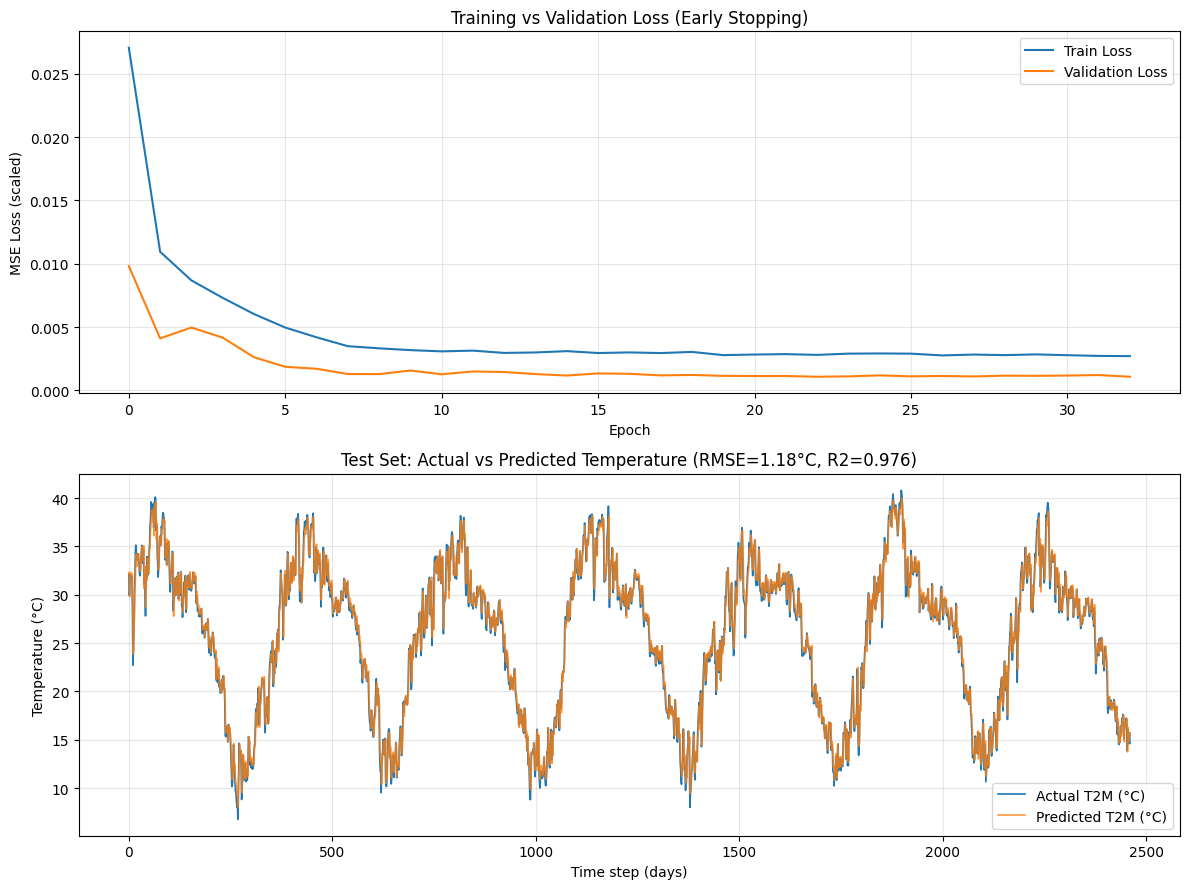

In [ ]:


import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import copy

# ----------------------------------------------------------------------------
# 0. Reproducibility & device
# ----------------------------------------------------------------------------
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ----------------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------------
CSV_PATH = "/content/POWER_Point_Daily_T2M_only.csv"
df = pd.read_csv(CSV_PATH)
df.columns = [c.strip() for c in df.columns]
target_col = df.columns[0]           # "T2M_Temperature_C"
df = df.dropna().reset_index(drop=True)

values = df[target_col].values.astype("float32").reshape(-1, 1)
print(f"Total data points: {len(values)}")

# ----------------------------------------------------------------------------
# 2. Scale data to [0, 1]
# ----------------------------------------------------------------------------
scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(values)

# ----------------------------------------------------------------------------
# 3. Build sliding-window sequences
# ----------------------------------------------------------------------------
LOOKBACK = 30   # use last 30 days to predict the next day

def make_sequences(data, lookback):
    X, y = [], []
    for i in range(len(data) - lookback):
        X.append(data[i:i + lookback])
        y.append(data[i + lookback])
    return np.array(X), np.array(y)

X, y = make_sequences(scaled, LOOKBACK)
print(f"Sequence shape: X={X.shape}, y={y.shape}")

# ----------------------------------------------------------------------------
# 4. Train / Validation / Test split (chronological — no shuffling for time series)
# ----------------------------------------------------------------------------
n = len(X)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[val_end:], y[val_end:]

print(f"Train: {len(X_train)}  Val: {len(X_val)}  Test: {len(X_test)}")

class SeqDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 32
train_loader = DataLoader(SeqDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(SeqDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(SeqDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

# ----------------------------------------------------------------------------
# 5. Attention-based LSTM model
# ----------------------------------------------------------------------------
class Attention(nn.Module):
    """Additive (Bahdanau-style) attention over LSTM hidden states."""
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, lstm_out):
        # lstm_out: (batch, seq_len, hidden_dim)
        energy = torch.tanh(self.attn(lstm_out))          # (batch, seq_len, hidden_dim)
        scores = self.v(energy).squeeze(-1)                # (batch, seq_len)
        weights = torch.softmax(scores, dim=1)              # (batch, seq_len)
        context = torch.bmm(weights.unsqueeze(1), lstm_out).squeeze(1)  # (batch, hidden_dim)
        return context, weights


class AttentionLSTM(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.attention = Attention(hidden_dim)
        self.fc1 = nn.Linear(hidden_dim, 32)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(32, 1)

    def forward(self, x):
        lstm_out, _ = self.lstm(x)              # (batch, seq_len, hidden_dim)
        context, attn_weights = self.attention(lstm_out)
        out = self.relu(self.fc1(context))
        out = self.dropout(out)
        out = self.fc2(out)                      # (batch, 1)
        return out, attn_weights


model = AttentionLSTM(input_dim=1, hidden_dim=64, num_layers=2, dropout=0.2).to(device)
print(model)

# ----------------------------------------------------------------------------
# 6. Training setup with EARLY STOPPING (auto-close epochs at minimum val loss)
# ----------------------------------------------------------------------------
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

MAX_EPOCHS = 200
PATIENCE = 10          # stop if val loss doesn't improve for this many epochs
best_val_loss = float("inf")
best_model_state = None
patience_counter = 0

history = {"train_loss": [], "val_loss": []}

for epoch in range(1, MAX_EPOCHS + 1):
    # ---- Train ----
    model.train()
    train_losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        pred, _ = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_losses.append(loss.item())
    train_loss = float(np.mean(train_losses))

    # ---- Validate ----
    model.eval()
    val_losses = []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred, _ = model(xb)
            val_losses.append(criterion(pred, yb).item())
    val_loss = float(np.mean(val_losses))

    scheduler.step(val_loss)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(f"Epoch {epoch:3d}/{MAX_EPOCHS} | train_loss={train_loss:.6f} | val_loss={val_loss:.6f}")

    # ---- Early stopping (auto-close epochs at minimum score) ----
    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\nEarly stopping triggered at epoch {epoch} "
                  f"(no val improvement for {PATIENCE} epochs). "
                  f"Best val_loss={best_val_loss:.6f}")
            break

# Restore best weights (the minimum-score checkpoint)
model.load_state_dict(best_model_state)
print(f"\nTraining auto-closed. Total epochs run: {epoch}. Best val_loss: {best_val_loss:.6f}")

# ----------------------------------------------------------------------------
# 7. Evaluation: Accuracy & Error metrics
# ----------------------------------------------------------------------------
def evaluate(loader):
    model.eval()
    preds, actuals = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            pred, _ = model(xb)
            preds.append(pred.cpu().numpy())
            actuals.append(yb.numpy())
    preds = np.concatenate(preds).reshape(-1, 1)
    actuals = np.concatenate(actuals).reshape(-1, 1)

    # Inverse-transform back to original temperature scale (°C)
    preds_inv = scaler.inverse_transform(preds)
    actuals_inv = scaler.inverse_transform(actuals)
    return preds_inv.flatten(), actuals_inv.flatten()

def print_metrics(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, 1e-6, y_true))) * 100
    r2 = r2_score(y_true, y_pred)
    accuracy_pct = max(0.0, 100 - mape)   # "accuracy" derived from error (100% - MAPE)

    print(f"\n--- {name} Set Metrics ---")
    print(f"MAE   (Mean Absolute Error)      : {mae:.4f} °C")
    print(f"RMSE  (Root Mean Squared Error)   : {rmse:.4f} °C")
    print(f"MAPE  (Mean Abs. % Error)         : {mape:.2f} %")
    print(f"R2 Score                          : {r2:.4f}")
    print(f"Accuracy (100 - MAPE)             : {accuracy_pct:.2f} %")
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape, "R2": r2, "Accuracy%": accuracy_pct}

train_pred, train_true = evaluate(train_loader)
val_pred, val_true = evaluate(val_loader)
test_pred, test_true = evaluate(test_loader)

train_metrics = print_metrics("Train", train_true, train_pred)
val_metrics = print_metrics("Validation", val_true, val_pred)
test_metrics = print_metrics("Test", test_true, test_pred)

# ----------------------------------------------------------------------------
# 8. Plots — Loss curve & Predicted vs Actual (test set)
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("Training vs Validation Loss (Early Stopping)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss (scaled)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(test_true, label="Actual T2M (°C)", linewidth=1.2)
axes[1].plot(test_pred, label="Predicted T2M (°C)", linewidth=1.2, alpha=0.8)
axes[1].set_title(f"Test Set: Actual vs Predicted Temperature "
                   f"(RMSE={test_metrics['RMSE']:.2f}°C, R2={test_metrics['R2']:.3f})")
axes[1].set_xlabel("Time step (days)")
axes[1].set_ylabel("Temperature (°C)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/attention_lstm_results.png", dpi=150)
print("\nSaved plot to /mnt/user-data/outputs/attention_lstm_results.png")

# ----------------------------------------------------------------------------
# 9. Save model
# ----------------------------------------------------------------------------
torch.save(model.state_dict(), "/mnt/user-data/outputs/attention_lstm_t2m.pt")
print("Saved model weights to /mnt/user-data/outputs/attention_lstm_t2m.pt")

print("\n================ FINAL SUMMARY ================")
print(f"Lookback window        : {LOOKBACK} days")
print(f"Epochs run (auto-closed): {epoch}")
print(f"Best validation loss    : {best_val_loss:.6f}")
print(f"Test RMSE               : {test_metrics['RMSE']:.4f} °C")
print(f"Test MAE                : {test_metrics['MAE']:.4f} °C")
print(f"Test Accuracy (100-MAPE): {test_metrics['Accuracy%']:.2f} %")
print(f"Test R2 Score           : {test_metrics['R2']:.4f}")

Layer Normalization with LSTM

```



In [ ]:


import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# ----------------------------------------------------------------------
# 0. Config
# ----------------------------------------------------------------------
CSV_PATH      = "/content/POWER_Point_Daily_T2M_only.csv"
TARGET_COL    = "T2M_Temperature_C"
WINDOW_SIZE   = 30          # days of history used to predict the next day
BATCH_SIZE    = 64
HIDDEN_SIZE   = 64
NUM_LAYERS    = 2
DROPOUT       = 0.2
LR            = 1e-3
MAX_EPOCHS    = 200         # upper bound — early stopping will usually stop sooner
PATIENCE      = 10          # epochs with no val-loss improvement before stopping
ACC_TOLERANCE = 0.5         # deg C — a prediction within +-0.5C counts as "correct"
SEED          = 42
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(SEED)
np.random.seed(SEED)


# ----------------------------------------------------------------------
# 1. Load data
# ----------------------------------------------------------------------
df = pd.read_csv(CSV_PATH)
series = df[TARGET_COL].astype("float32").values.reshape(-1, 1)
print(f"Loaded {len(series)} daily temperature readings.")

# ----------------------------------------------------------------------
# 2. Scale (fit scaler on train portion only, to avoid leakage)
# ----------------------------------------------------------------------
n_total = len(series)
n_train = int(n_total * 0.70)
n_val   = int(n_total * 0.15)
n_test  = n_total - n_train - n_val

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(series[:n_train])
scaled = scaler.transform(series)


def make_sequences(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i:i + window, 0])
        y.append(data[i + window, 0])
    return np.array(X, dtype="float32"), np.array(y, dtype="float32")


X_all, y_all = make_sequences(scaled, WINDOW_SIZE)

# Chronological split, accounting for the window offset
train_end = n_train - WINDOW_SIZE
val_end   = train_end + n_val

X_train, y_train = X_all[:train_end], y_all[:train_end]
X_val,   y_val   = X_all[train_end:val_end], y_all[train_end:val_end]
X_test,  y_test  = X_all[val_end:], y_all[val_end:]

print(f"Train seq: {len(X_train)}  Val seq: {len(X_val)}  Test seq: {len(X_test)}")


class SeqDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).unsqueeze(-1)   # (N, window, 1)
        self.y = torch.from_numpy(y).unsqueeze(-1)   # (N, 1)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_loader = DataLoader(SeqDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(SeqDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(SeqDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)


# ----------------------------------------------------------------------
# 3. Model: LSTM + LayerNorm + FC head
# ----------------------------------------------------------------------
class LayerNormLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=HIDDEN_SIZE,
                 num_layers=NUM_LAYERS, dropout=DROPOUT):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        # LayerNorm normalizes across the hidden-feature dimension of the
        # LSTM's final-timestep output, stabilizing/accelerating training.
        self.layer_norm = nn.LayerNorm(hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x: (batch, window, 1)
        lstm_out, _ = self.lstm(x)          # (batch, window, hidden)
        last_step = lstm_out[:, -1, :]       # (batch, hidden)
        normed = self.layer_norm(last_step)  # LayerNorm applied here
        out = self.dropout(normed)
        return self.fc(out)                  # (batch, 1)


model = LayerNormLSTM().to(DEVICE)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

print(model)


# ----------------------------------------------------------------------
# 4. Train with early stopping ("auto closed epochs with minimum score")
# ----------------------------------------------------------------------
def run_epoch(loader, train_mode):
    model.train() if train_mode else model.eval()
    total_loss, n_batches = 0.0, 0
    context = torch.enable_grad() if train_mode else torch.no_grad()
    with context:
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if train_mode:
                optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            if train_mode:
                loss.backward()
                optimizer.step()
            total_loss += loss.item()
            n_batches += 1
    return total_loss / max(n_batches, 1)


best_val_loss = float("inf")
best_state = None
epochs_no_improve = 0
history = {"train_loss": [], "val_loss": []}

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = run_epoch(train_loader, train_mode=True)
    val_loss = run_epoch(val_loader, train_mode=False)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    improved = val_loss < best_val_loss - 1e-6
    if improved:
        best_val_loss = val_loss
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    print(f"Epoch {epoch:3d} | train_loss={train_loss:.6f} | "
          f"val_loss={val_loss:.6f}{'  *best*' if improved else ''}")

    if epochs_no_improve >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch} "
              f"(no val-loss improvement for {PATIENCE} epochs).")
        print(f"Restoring best weights (min val_loss = {best_val_loss:.6f}).")
        break

# Restore the best (minimum validation loss) model
if best_state is not None:
    model.load_state_dict(best_state)


# ----------------------------------------------------------------------
# 5. Evaluate on the test set: error metrics + tolerance-based accuracy
# ----------------------------------------------------------------------
model.eval()
preds_scaled, trues_scaled = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        out = model(xb).cpu().numpy()
        preds_scaled.append(out)
        trues_scaled.append(yb.numpy())

preds_scaled = np.concatenate(preds_scaled).reshape(-1, 1)
trues_scaled = np.concatenate(trues_scaled).reshape(-1, 1)

# Undo MinMax scaling -> back to real degrees Celsius
preds = scaler.inverse_transform(preds_scaled).flatten()
trues = scaler.inverse_transform(trues_scaled).flatten()

mse = mean_squared_error(trues, preds)
rmse = np.sqrt(mse)
mae = mean_absolute_error(trues, preds)
mape = np.mean(np.abs((trues - preds) / np.clip(np.abs(trues), 1e-6, None))) * 100

# Regression "accuracy": % of predictions within +-ACC_TOLERANCE degrees C
within_tol = np.abs(preds - trues) <= ACC_TOLERANCE
accuracy_pct = within_tol.mean() * 100

# R^2 (coefficient of determination) as an extra goodness-of-fit measure
ss_res = np.sum((trues - preds) ** 2)
ss_tot = np.sum((trues - trues.mean()) ** 2)
r2 = 1 - ss_res / ss_tot

print("\n===== Test-set performance =====")
print(f"MSE                         : {mse:.4f}")
print(f"RMSE                        : {rmse:.4f} deg C")
print(f"MAE                         : {mae:.4f} deg C")
print(f"MAPE                        : {mape:.2f}%")
print(f"R^2 score                   : {r2:.4f}")
print(f"Accuracy (within +-{ACC_TOLERANCE}C)   : {accuracy_pct:.2f}%")

print("\nSample predictions vs. actual (first 10 test points):")
for i in range(min(10, len(preds))):
    print(f"  true={trues[i]:.2f}C  pred={preds[i]:.2f}C  "
          f"abs_err={abs(trues[i]-preds[i]):.2f}C")

Loaded 16436 daily temperature readings.
Train seq: 11475  Val seq: 2465  Test seq: 2466
LayerNormLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (layer_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
Epoch   1 | train_loss=0.026661 | val_loss=0.003220  *best*
Epoch   2 | train_loss=0.006978 | val_loss=0.002816  *best*
Epoch   3 | train_loss=0.005771 | val_loss=0.002620  *best*
Epoch   4 | train_loss=0.005271 | val_loss=0.002626
Epoch   5 | train_loss=0.005068 | val_loss=0.002563  *best*
Epoch   6 | train_loss=0.004785 | val_loss=0.004842
Epoch   7 | train_loss=0.004463 | val_loss=0.001925  *best*
Epoch   8 | train_loss=0.004075 | val_loss=0.002110
Epoch   9 | train_loss=0.003876 | val_loss=0.001789  *best*
Epoch  10 | train_loss=0.003515 | val_loss=0.001616  *best*
Epoch  11 | train_loss=0.003312 | val_loss=0.002512
Epoch  12 | train_loss=0.0034

Residual LSTM

Loaded 16436 daily T2M records.
Train: 11812 | Val: 1312 | Test: 3282
ResidualLSTM(
  (blocks): ModuleList(
    (0): ResidualLSTMBlock(
      (lstm): LSTM(1, 64, batch_first=True)
      (proj): Linear(in_features=1, out_features=64, bias=True)
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.2, inplace=False)
    )
    (1-2): 2 x ResidualLSTMBlock(
      (lstm): LSTM(64, 64, batch_first=True)
      (proj): Identity()
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.2, inplace=False)
    )
  )
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
Epoch   1/200 | train_loss=0.053726 | val_loss=0.013925
Epoch   2/200 | train_loss=0.006286 | val_loss=0.005296
Epoch   3/200 | train_loss=0.004926 | val_loss=0.003507
Epoch   4/200 | train_loss=0.004564 | val_loss=0.007377
Epoch   5/200 | train_loss=0.004033 | val_loss=0.005916
Epoch   6/200 | train_loss=0.003768 | val_loss=0.004094
Epoch   7/20

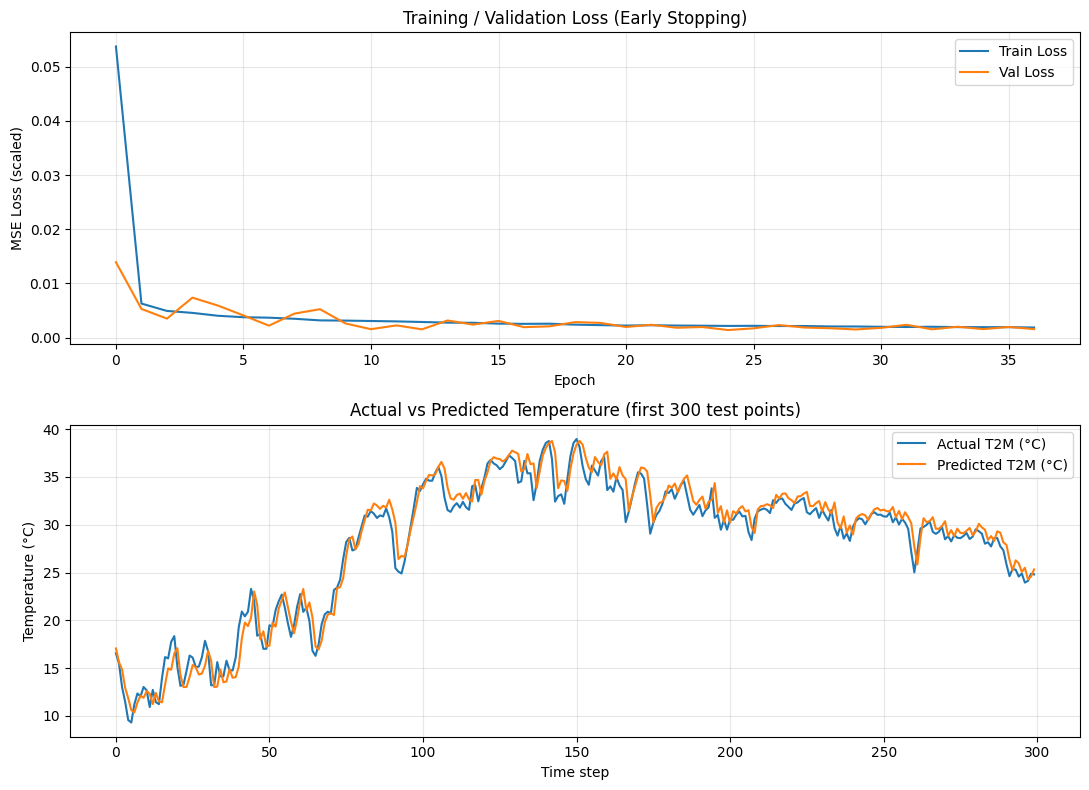

In [ ]:


import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import copy

# ----------------------------- Config ----------------------------------- #
CSV_PATH      = "/content/POWER_Point_Daily_T2M_only.csv"
SEQ_LEN       = 30          # look-back window (days)
BATCH_SIZE    = 64
HIDDEN_SIZE   = 64
NUM_LAYERS    = 3           # number of residual LSTM blocks
DROPOUT       = 0.2
LR            = 1e-3
MAX_EPOCHS    = 200         # hard ceiling
PATIENCE      = 12          # early-stopping patience (auto-closes epochs)
MIN_DELTA     = 1e-5        # minimum improvement in val loss to reset patience
TRAIN_SPLIT   = 0.8
VAL_SPLIT     = 0.1         # taken out of the training portion
SEED          = 42
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(SEED)
np.random.seed(SEED)

# ------------------------------ Data ------------------------------------- #
df = pd.read_csv(CSV_PATH)
series = df.iloc[:, 0].astype(float).values.reshape(-1, 1)
print(f"Loaded {len(series)} daily T2M records.")

scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(series)


def make_sequences(data, seq_len):
    X, y = [], []
    for i in range(len(data) - seq_len):
        X.append(data[i:i + seq_len])
        y.append(data[i + seq_len])
    return np.array(X), np.array(y)


X, y = make_sequences(scaled, SEQ_LEN)

n_total = len(X)
n_train = int(n_total * TRAIN_SPLIT)
n_val = int(n_train * VAL_SPLIT)
n_train_final = n_train - n_val

X_train, y_train = X[:n_train_final], y[:n_train_final]
X_val, y_val = X[n_train_final:n_train], y[n_train_final:n_train]
X_test, y_test = X[n_train:], y[n_train:]

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")


class SeqDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_loader = DataLoader(SeqDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(SeqDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(SeqDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)


# --------------------------- Residual LSTM -------------------------------- #
class ResidualLSTMBlock(nn.Module):
    """One LSTM layer wrapped with a residual (skip) connection.
    If input_size != hidden_size, a linear projection aligns dimensions
    so the residual add is valid."""

    def __init__(self, input_size, hidden_size, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.needs_proj = input_size != hidden_size
        self.proj = nn.Linear(input_size, hidden_size) if self.needs_proj else nn.Identity()
        self.norm = nn.LayerNorm(hidden_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out, _ = self.lstm(x)               # (B, T, H)
        residual = self.proj(x)             # (B, T, H)
        out = self.norm(out + residual)      # residual connection + norm
        return self.dropout(out)


class ResidualLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=3, dropout=0.2):
        super().__init__()
        blocks = []
        in_size = input_size
        for _ in range(num_layers):
            blocks.append(ResidualLSTMBlock(in_size, hidden_size, dropout))
            in_size = hidden_size
        self.blocks = nn.ModuleList(blocks)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        last_step = x[:, -1, :]          # take last time step
        return self.fc(last_step)


model = ResidualLSTM(input_size=1, hidden_size=HIDDEN_SIZE,
                      num_layers=NUM_LAYERS, dropout=DROPOUT).to(DEVICE)
print(model)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min",
                                                        factor=0.5, patience=5)

# ------------------------- Training w/ Early Stopping --------------------- #
best_val_loss = float("inf")
best_state = None
patience_counter = 0
history = {"train_loss": [], "val_loss": []}

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_losses.append(loss.item())

    model.eval()
    val_losses = []
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb)
            val_losses.append(criterion(pred, yb).item())

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    scheduler.step(val_loss)

    print(f"Epoch {epoch:3d}/{MAX_EPOCHS} | train_loss={train_loss:.6f} | val_loss={val_loss:.6f}")

    # ---- Early stopping (auto-close epochs at minimum validation score) ---
    if val_loss < best_val_loss - MIN_DELTA:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\nEarly stopping triggered at epoch {epoch} "
                  f"(no improvement for {PATIENCE} epochs). "
                  f"Best val_loss={best_val_loss:.6f}")
            break

# Restore best weights found during training
model.load_state_dict(best_state)

# ------------------------------ Evaluation --------------------------------- #
model.eval()
preds, actuals = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        pred = model(xb).cpu().numpy()
        preds.append(pred)
        actuals.append(yb.numpy())

preds = np.concatenate(preds, axis=0)
actuals = np.concatenate(actuals, axis=0)

# Inverse-transform back to original °C scale
preds_c = scaler.inverse_transform(preds)
actuals_c = scaler.inverse_transform(actuals)

mae = mean_absolute_error(actuals_c, preds_c)
rmse = np.sqrt(mean_squared_error(actuals_c, preds_c))
mape = np.mean(np.abs((actuals_c - preds_c) / actuals_c)) * 100
r2 = r2_score(actuals_c, preds_c)
accuracy = 100 - mape   # "accuracy" expressed as 100 - MAPE, common for regression

print("\n================ TEST SET RESULTS ================")
print(f"MAE   (Mean Absolute Error)       : {mae:.4f} °C")
print(f"RMSE  (Root Mean Squared Error)   : {rmse:.4f} °C")
print(f"MAPE  (Mean Absolute % Error)     : {mape:.2f} %")
print(f"R^2 Score                         : {r2:.4f}")
print(f"Accuracy (100 - MAPE)             : {accuracy:.2f} %")
print("====================================================")

# ------------------------------- Plots ------------------------------------- #
fig, axes = plt.subplots(2, 1, figsize=(11, 8))

axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Training / Validation Loss (Early Stopping)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss (scaled)")
axes[0].legend()
axes[0].grid(alpha=0.3)

n_show = min(300, len(preds_c))
axes[1].plot(actuals_c[:n_show], label="Actual T2M (°C)")
axes[1].plot(preds_c[:n_show], label="Predicted T2M (°C)")
axes[1].set_title(f"Actual vs Predicted Temperature (first {n_show} test points)")
axes[1].set_xlabel("Time step")
axes[1].set_ylabel("Temperature (°C)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/mnt/user-data/outputs/residual_lstm_results.png", dpi=150)
print("\nSaved plot to /mnt/user-data/outputs/residual_lstm_results.png")

torch.save(model.state_dict(), "/mnt/user-data/outputs/residual_lstm_t2m.pt")
print("Saved trained model to /mnt/user-data/outputs/residual_lstm_t2m.pt")

### Variation of Residual LSTM

### Deep Residual LSTM

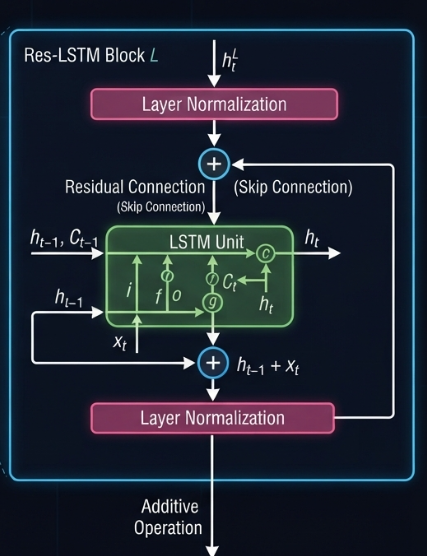

In [ ]:


import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

# ----------------------------------------------------------------------
# 1. Config
# ----------------------------------------------------------------------
CSV_PATH   = "/content/POWER_Point_Daily_T2M_only.csv"
WINDOW     = 30          # how many past days the model looks at
HIDDEN     = 64          # LSTM hidden size (kept constant across layers for residual add)
NUM_LAYERS = 4           # number of stacked residual LSTM blocks
BATCH_SIZE = 64
EPOCHS     = 40
LR         = 1e-3
DEVICE     = "cuda" if torch.cuda.is_available() else "cpu"

# ----------------------------------------------------------------------
# 2. Load & prepare data
# ----------------------------------------------------------------------
df = pd.read_csv(CSV_PATH)
series = df["T2M_Temperature_C"].values.astype("float32")
print(f"Loaded {len(series)} daily temperature readings")

# Chronological split: 70% train / 15% val / 15% test (no shuffling - it's a time series)
n = len(series)
train_end = int(n * 0.70)
val_end   = int(n * 0.85)

train_raw = series[:train_end]
val_raw   = series[train_end - WINDOW:val_end]   # keep WINDOW lookback context
test_raw  = series[val_end - WINDOW:]

# Normalize using ONLY train statistics (avoid leakage)
mu, sigma = train_raw.mean(), train_raw.std()
norm = lambda x: (x - mu) / sigma
denorm = lambda x: x * sigma + mu

train_n, val_n, test_n = norm(train_raw), norm(val_raw), norm(test_raw)


def make_windows(arr, window):
    X, y = [], []
    for i in range(len(arr) - window):
        X.append(arr[i:i + window])
        y.append(arr[i + window])
    X = np.array(X, dtype="float32")[..., None]   # (samples, window, 1 feature)
    y = np.array(y, dtype="float32")[..., None]   # (samples, 1)
    return X, y


X_train, y_train = make_windows(train_n, WINDOW)
X_val,   y_val   = make_windows(val_n,   WINDOW)
X_test,  y_test  = make_windows(test_n,  WINDOW)
print(f"Train windows: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")


class SeqDataset(Dataset):
    def __init__(self, X, y):
        self.X, self.y = torch.from_numpy(X), torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_loader = DataLoader(SeqDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(SeqDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(SeqDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)


# ----------------------------------------------------------------------
# 3. Deep Residual LSTM model
# ----------------------------------------------------------------------
class ResidualLSTMBlock(nn.Module):
    """One LSTM layer + LayerNorm + residual (skip) connection around it."""

    def __init__(self, hidden_size, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(hidden_size, hidden_size, batch_first=True)
        self.norm = nn.LayerNorm(hidden_size)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.drop(out)
        return self.norm(x + out)          # <-- the residual add from the diagram


class DeepResidualLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=HIDDEN, num_layers=NUM_LAYERS, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(input_size, hidden_size)   # project to hidden dim so residual add works
        self.blocks = nn.ModuleList([
            ResidualLSTMBlock(hidden_size, dropout) for _ in range(num_layers)
        ])
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.input_proj(x)             # (batch, window, hidden)
        for block in self.blocks:
            h = block(h)
        last_step = h[:, -1, :]            # use the final time step to predict next value
        return self.head(last_step)


model = DeepResidualLSTM().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Total trainable parameters: {n_params:,}")

# ----------------------------------------------------------------------
# 4. Train
# ----------------------------------------------------------------------
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

history = {"train_loss": [], "val_loss": []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        running += loss.item() * xb.size(0)
    train_loss = running / len(train_loader.dataset)

    model.eval()
    running = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb)
            running += criterion(pred, yb).item() * xb.size(0)
    val_loss = running / len(val_loader.dataset)
    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d}/{EPOCHS} | train MSE (norm): {train_loss:.5f} | val MSE (norm): {val_loss:.5f}")

# ----------------------------------------------------------------------
# 5. Evaluate on test set (metrics computed back in real deg C, not normalized)
# ----------------------------------------------------------------------
model.eval()
preds_n, actual_n = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        pred = model(xb).cpu().numpy()
        preds_n.append(pred)
        actual_n.append(yb.numpy())
preds_n = np.concatenate(preds_n).flatten()
actual_n = np.concatenate(actual_n).flatten()

preds = denorm(preds_n)
actual = denorm(actual_n)

mse = float(np.mean((preds - actual) ** 2))
rmse = float(np.sqrt(mse))
mae = float(np.mean(np.abs(preds - actual)))
mape = float(np.mean(np.abs((preds - actual) / actual)) * 100)
ss_res = np.sum((actual - preds) ** 2)
ss_tot = np.sum((actual - actual.mean()) ** 2)
r2 = float(1 - ss_res / ss_tot)

# Directional accuracy: did we get the up/down move (vs. previous actual day) right?
prev_actual = actual[:-1]
next_actual = actual[1:]
next_pred = preds[1:]
true_dir = np.sign(next_actual - prev_actual)
pred_dir = np.sign(next_pred - prev_actual)
dir_acc = float(np.mean(true_dir == pred_dir) * 100)

# "Tolerance accuracy": % of predictions within +-1 degree C of actual
tol_acc_1c = float(np.mean(np.abs(preds - actual) <= 1.0) * 100)
tol_acc_2c = float(np.mean(np.abs(preds - actual) <= 2.0) * 100)

print("\n================ TEST SET METRICS ================")
print(f"MSE   : {mse:.4f}  (deg C^2)")
print(f"RMSE  : {rmse:.4f}  (deg C)")
print(f"MAE   : {mae:.4f}  (deg C)")
print(f"MAPE  : {mape:.2f} %")
print(f"R^2   : {r2:.4f}")
print(f"Directional accuracy (up/down vs previous day): {dir_acc:.2f}%")
print(f"Tolerance accuracy (within +-1C) : {tol_acc_1c:.2f}%")
print(f"Tolerance accuracy (within +-2C) : {tol_acc_2c:.2f}%")



Loaded 16436 daily temperature readings
Train windows: (11475, 30, 1), Val: (2465, 30, 1), Test: (2466, 30, 1)
DeepResidualLSTM(
  (input_proj): Linear(in_features=1, out_features=64, bias=True)
  (blocks): ModuleList(
    (0-3): 4 x ResidualLSTMBlock(
      (lstm): LSTM(64, 64, batch_first=True)
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (drop): Dropout(p=0.1, inplace=False)
    )
  )
  (head): Linear(in_features=64, out_features=1, bias=True)
)
Total trainable parameters: 133,825
Epoch   1/40 | train MSE (norm): 0.04154 | val MSE (norm): 0.02354
Epoch   5/40 | train MSE (norm): 0.02486 | val MSE (norm): 0.02205
Epoch  10/40 | train MSE (norm): 0.02394 | val MSE (norm): 0.02160
Epoch  15/40 | train MSE (norm): 0.02345 | val MSE (norm): 0.02106
Epoch  20/40 | train MSE (norm): 0.02317 | val MSE (norm): 0.02127
Epoch  25/40 | train MSE (norm): 0.02295 | val MSE (norm): 0.02086
Epoch  30/40 | train MSE (norm): 0.02289 | val MSE (norm): 0.02080
Epoch  35/40 |

### Residual Connection-Enhanced ConvLSTM (RC-ConvLSTM)

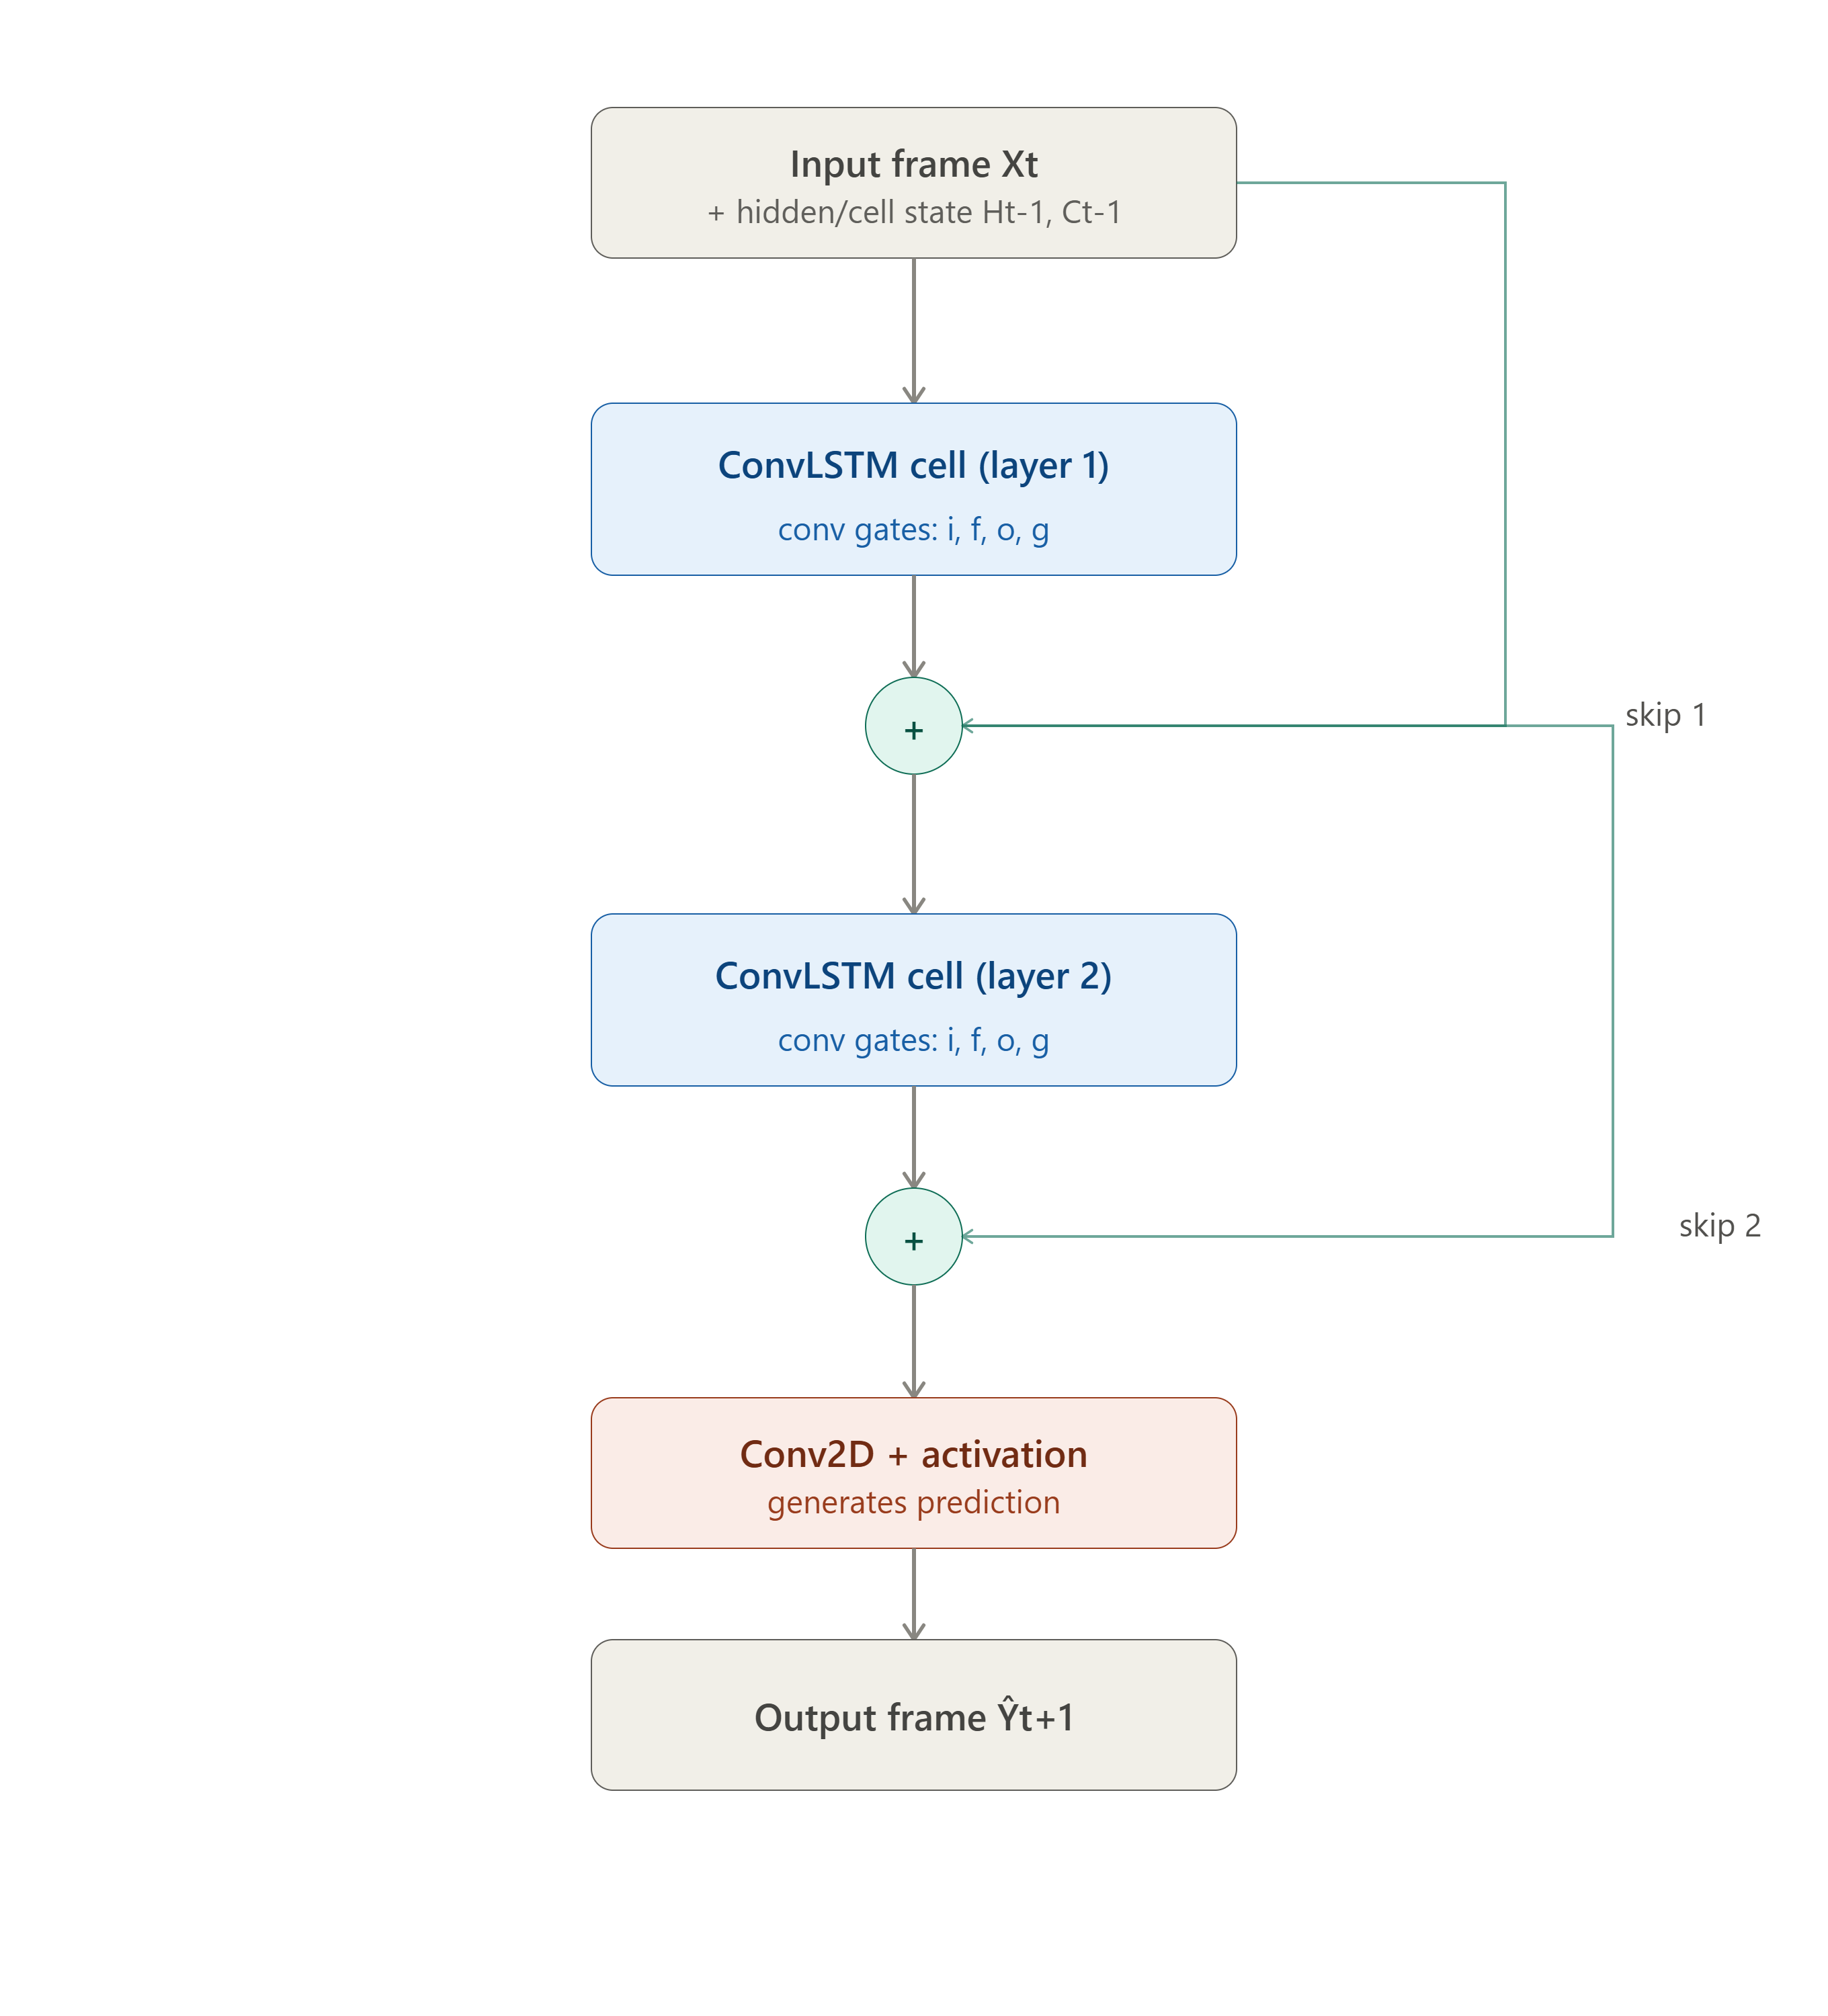

In [ ]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import json

tf.random.set_seed(42)
np.random.seed(42)

# ---------------------------------------------------------
# 1. Load data
# ---------------------------------------------------------
df = pd.read_csv("/content/POWER_Point_Daily_T2M_only.csv")
series = df["T2M_Temperature_C"].values.astype("float32").reshape(-1, 1)
print("Total records:", len(series))

# ---------------------------------------------------------
# 2. Scale data
# ---------------------------------------------------------
scaler = MinMaxScaler(feature_range=(0, 1))
scaled = scaler.fit_transform(series)

# ---------------------------------------------------------
# 3. Create sliding-window supervised sequences
# ---------------------------------------------------------
WINDOW = 30  # use previous 30 days to predict next day

def make_sequences(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i:i + window, 0])
        y.append(data[i + window, 0])
    return np.array(X), np.array(y)

X, y = make_sequences(scaled, WINDOW)
X = X.reshape((X.shape[0], X.shape[1], 1))
print("X shape:", X.shape, "y shape:", y.shape)

# ---------------------------------------------------------
# 4. Chronological train / val / test split (70/15/15)
# ---------------------------------------------------------
n = len(X)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[val_end:], y[val_end:]

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

# ---------------------------------------------------------
# 5. Build Attention-Enhanced Residual LSTM
# ---------------------------------------------------------
def residual_lstm_block(x, units, name):
    """LSTM block with a residual (skip) connection."""
    shortcut = x
    out = layers.LSTM(units, return_sequences=True, name=f"{name}_lstm")(x)
    out = layers.LayerNormalization(name=f"{name}_ln")(out)
    out = layers.Dropout(0.2, name=f"{name}_drop")(out)
    # project shortcut if dimensions differ
    if shortcut.shape[-1] != units:
        shortcut = layers.Dense(units, name=f"{name}_proj")(shortcut)
    out = layers.Add(name=f"{name}_add")([shortcut, out])
    return out

def build_model(window, units=64):
    inputs = layers.Input(shape=(window, 1), name="input")

    x = residual_lstm_block(inputs, units, "res1")
    x = residual_lstm_block(x, units, "res2")

    # ---- Attention mechanism (Bahdanau-style additive attention) ----
    score = layers.Dense(units, activation="tanh", name="attn_score")(x)
    score = layers.Dense(1, name="attn_energy")(score)
    attn_weights = layers.Softmax(axis=1, name="attn_weights")(score)
    context = layers.Multiply(name="attn_context_mul")([x, attn_weights])
    context = layers.Lambda(lambda t: tf.reduce_sum(t, axis=1), name="attn_context_sum")(context)

    # ---- Final residual dense head ----
    d = layers.Dense(32, activation="relu", name="dense1")(context)
    shortcut2 = layers.Dense(32, name="dense_shortcut")(context)
    d = layers.Add(name="dense_residual")([d, shortcut2])
    d = layers.Dropout(0.2, name="final_drop")(d)
    outputs = layers.Dense(1, name="output")(d)

    model = keras.Model(inputs, outputs, name="Attention_Residual_LSTM")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse",
        metrics=["mae", keras.metrics.RootMeanSquaredError(name="rmse")],
    )
    return model

model = build_model(WINDOW, units=64)
model.summary()

# ---------------------------------------------------------
# 6. Train
# ---------------------------------------------------------
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=2,
)

# ---------------------------------------------------------
# 7. Evaluate on test set
# ---------------------------------------------------------
test_loss, test_mae, test_rmse = model.evaluate(X_test, y_test, verbose=0)

y_pred_scaled = model.predict(X_test, verbose=0)
y_pred = scaler.inverse_transform(y_pred_scaled)
y_true = scaler.inverse_transform(y_test.reshape(-1, 1))

rmse_c = np.sqrt(mean_squared_error(y_true, y_pred))
mae_c = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# "Accuracy" for regression -> 100 - MAPE (a common practical proxy)
accuracy_pct = 100 - mape

print("\n===== TEST METRICS (scaled 0-1 space) =====")
print(f"Test Loss (MSE, scaled): {test_loss:.6f}")
print(f"Test MAE (scaled):       {test_mae:.6f}")
print(f"Test RMSE (scaled):      {test_rmse:.6f}")

print("\n===== TEST METRICS (original °C space) =====")
print(f"RMSE: {rmse_c:.4f} °C")
print(f"MAE:  {mae_c:.4f} °C")
print(f"R^2 Score: {r2:.4f}")
print(f"MAPE: {mape:.2f} %")
print(f"Accuracy (100 - MAPE): {accuracy_pct:.2f} %")



Total records: 16436
X shape: (16406, 30, 1) y shape: (16406,)
Train: (11484, 30, 1) Val: (2461, 30, 1) Test: (2461, 30, 1)


Model: "Attention_Residual_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 30, 1)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res1_lstm (LSTM)    │ (None, 30, 64)    │     16,896 │ input[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res1_ln             │ (None, 30, 64)    │        128 │ res1_lstm[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res1_proj (Dense)   │ (None, 30, 64)    │        128 │ input[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res1_drop (Dropout) │ (None, 30, 64)    │          0 │ res1_ln[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res1_add (Add)      │ (None, 30, 64)    │          0 │ res1_proj[0][0],  │
│                     │                   │            │ res1_drop[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res2_lstm (LSTM)    │ (None, 30, 64)    │     33,024 │ res1_add[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res2_ln             │ (None, 30, 64)    │        128 │ res2_lstm[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res2_drop (Dropout) │ (None, 30, 64)    │          0 │ res2_ln[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ res2_add (Add)      │ (None, 30, 64)    │          0 │ res1_add[0][0],   │
│                     │                   │            │ res2_drop[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_score (Dense)  │ (None, 30, 64)    │      4,160 │ res2_add[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_energy (Dense) │ (None, 30, 1)     │         65 │ attn_score[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_weights        │ (None, 30, 1)     │          0 │ attn_energy[0][0] │
│ (Softmax)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_context_mul    │ (None, 30, 64)    │          0 │ res2_add[0][0],   │
│ (Multiply)          │                   │            │ attn_weights[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attn_context_sum    │ (None, 64)        │          0 │ attn_context_mul… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1 (Dense)      │ (None, 32)        │      2,080 │ attn_context_sum… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_shortcut      │ (None, 32)        │      2,080 │ attn_context_sum… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_residual      │ (None, 32)        │          0 │ dense1[0][0],     │
│ (Add)               │                   │            │ dense_shortcut[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ final_drop          │ (None, 32)        │          0 │ dense_residual[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │         33 │ final_drop[0][0]

 Total params: 58,722 (229.38 KB)

 Trainable params: 58,722 (229.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
359/359 - 22s - 61ms/step - loss: 0.3375 - mae: 0.3477 - rmse: 0.5809 - val_loss: 0.0055 - val_mae: 0.0599 - val_rmse: 0.0741 - learning_rate: 0.0010
Epoch 2/100
359/359 - 17s - 46ms/step - loss: 0.0473 - mae: 0.1726 - rmse: 0.2176 - val_loss: 0.0265 - val_mae: 0.1458 - val_rmse: 0.1629 - learning_rate: 0.0010
Epoch 3/100
359/359 - 7s - 21ms/step - loss: 0.0319 - mae: 0.1416 - rmse: 0.1786 - val_loss: 0.0045 - val_mae: 0.0527 - val_rmse: 0.0668 - learning_rate: 0.0010
Epoch 4/100
359/359 - 5s - 14ms/step - loss: 0.0260 - mae: 0.1285 - rmse: 0.1612 - val_loss: 0.0057 - val_mae: 0.0603 - val_rmse: 0.0753 - learning_rate: 0.0010
Epoch 5/100
359/359 - 6s - 17ms/step - loss: 0.0230 - mae: 0.1202 - rmse: 0.1515 - val_loss: 0.0047 - val_mae: 0.0540 - val_rmse: 0.0687 - learning_rate: 0.0010
Epoch 6/100
359/359 - 5s - 14ms/step - loss: 0.0202 - mae: 0.1132 - rmse: 0.1422 - val_loss: 0.0041 - val_mae: 0.0504 - val_rmse: 0.0642 - learning_rate: 0.0010
Epoch 7/100
359/359 - 6s - 17ms/

### Residual LSTM with Projection

residual_lstm_projection_architecture.svg

In [3]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr
import warnings

warnings.filterwarnings('ignore')

# 1. Hyperparameters
SEQ_LEN = 30
BATCH_SIZE = 64
HIDDEN_SIZE = 32
PROJ_SIZE = 1
NUM_LAYERS = 1
LEARNING_RATE = 0.005
MAX_EPOCHS = 100
PATIENCE = 10

# 2. Load and Preprocess Data
df = pd.read_csv("/content/POWER_Point_Daily_T2M_only.csv")
data = df['T2M_Temperature_C'].values.reshape(-1, 1)

scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(data)

def create_sequences(data, seq_len):
    xs, ys = [], []
    for i in range(len(data) - seq_len):
        xs.append(data[i:i+seq_len])
        ys.append(data[i+seq_len])
    return np.array(xs), np.array(ys)

X, y = create_sequences(data_scaled, SEQ_LEN)

# Split into 70% Train, 15% Validation, 15% Test
train_size = int(len(X) * 0.7)
val_size = int(len(X) * 0.15)

X_train, y_train = X[:train_size], y[:train_size]
X_val, y_val = X[train_size:train_size+val_size], y[train_size:train_size+val_size]
X_test, y_test = X[train_size+val_size:], y[train_size+val_size:]

train_loader = DataLoader(TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                                        torch.tensor(y_train, dtype=torch.float32)),
                          batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val, dtype=torch.float32),
                                      torch.tensor(y_val, dtype=torch.float32)),
                        batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.tensor(X_test, dtype=torch.float32),
                                       torch.tensor(y_test, dtype=torch.float32)),
                         batch_size=BATCH_SIZE, shuffle=False)

# 3. Define ResidualLSTM with Projection
class ResidualLSTMWithProjection(nn.Module):
    def __init__(self, input_size, hidden_size, proj_size, num_layers):
        super().__init__()
        # PyTorch LSTM supports native projection sizes
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, proj_size=proj_size)
        self.fc = nn.Linear(proj_size, 1)

    def forward(self, x):
        # x shape: (batch_size, seq_len, input_size)
        lstm_out, _ = self.lstm(x)
        # Residual connection: Add input to projected LSTM output
        res_out = lstm_out + x
        # Extract the last time step for prediction
        out = self.fc(res_out[:, -1, :])
        return out

model = ResidualLSTMWithProjection(1, HIDDEN_SIZE, PROJ_SIZE, NUM_LAYERS)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.MSELoss()

# 4. Training Loop with Early Stopping
best_val_loss = float('inf')
patience_counter = 0
best_epoch = 0

for epoch in range(MAX_EPOCHS):
    model.train()
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        preds = model(batch_x)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            preds = model(batch_x)
            val_loss += criterion(preds, batch_y).item()
    val_loss /= len(val_loader)

    # Auto-stop logic
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        best_epoch = epoch + 1
        torch.save(model.state_dict(), "best_reslstm_model.pth")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        break

# 5. Evaluation
model.load_state_dict(torch.load("best_reslstm_model.pth"))
model.eval()

predictions, actuals = [], []
with torch.no_grad():
    for batch_x, batch_y in test_loader:
        preds = model(batch_x)
        predictions.append(preds.numpy())
        actuals.append(batch_y.numpy())

predictions = np.concatenate(predictions)
actuals = np.concatenate(actuals)

# Inverse transform to original scale
preds_inv = scaler.inverse_transform(predictions)
actuals_inv = scaler.inverse_transform(actuals)

# Calculate Metrics
rmse = np.sqrt(mean_squared_error(actuals_inv, preds_inv))
mae = mean_absolute_error(actuals_inv, preds_inv)
r2 = r2_score(actuals_inv, preds_inv)
corr, _ = pearsonr(actuals_inv.flatten(), preds_inv.flatten())

print(f"Stopped at Epoch: {best_epoch + patience_counter}")
print(f"Best Epoch: {best_epoch}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R^2: {r2:.4f}")
print(f"Corr: {corr:.4f}")

Stopped at Epoch: 36
Best Epoch: 26
RMSE: 1.2072
MAE: 0.9047
R^2: 0.9748
Corr: 0.9873
